# Primera baseline OLS — propiedades usadas



In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown
# Configuración única del paquete para ejecutar desde la raíz o el notebook.
carpeta_paquete = next((c for p in (Path.cwd(), *Path.cwd().parents)
    for c in (p, p / "Ventas/Propiedades_Usadas")
    if (c / "scripts/__init__.py").is_file()), None)
if carpeta_paquete is None:
    raise RuntimeError("Ejecutar el notebook dentro del proyecto Moscow_EDA.")
if str(carpeta_paquete) not in sys.path:
    sys.path.insert(0, str(carpeta_paquete))
from scripts.contrato_datasets import (
    CARPETA_PROYECTO, DATA_DIR as DATOS_PROYECTO, DATASETS, SCRIPTS_DIR, RAIZ as raiz,
)
base = CARPETA_PROYECTO
from scripts import baseline_ols as b
print("Preparación verificada. No se leen datos de Test.")

from scripts.almacenamiento_mlflow import SesionTemporal, leer_json, RUN_TRANSFORMACION
sesion = SesionTemporal()


Preparación verificada. No se leen datos de Test.


## 1. Carga y contrato

Único CSV leído: `data/train_transformado.csv`. Se valida su SHA-256 contra el contrato fuente del dataset congelado y se respetan las 177 predictoras exportadas. `price_rub` permanece en RUB, sin logaritmo ni nueva transformación. `id`, `date_posted_dt` y `dataset_split` son auxiliares, no predictores.


In [2]:
with sesion.paso():
    X, y, contexto = b.cargar_train(base)
    print(f"Train: {len(y):,} filas; {X.shape[1]} predictoras; objetivo: price_rub (RUB)")
    print("SHA-256:", contexto["dataset_sha256"])
    print("Auxiliares excluidas:", contexto["auxiliares_excluidas"])
    display(X.head())


Train: 37,984 filas; 177 predictoras; objetivo: price_rub (RUB)
SHA-256: 12fe313ce35f77af04ba22c09c4327058fe4850d1fa9a863a1755f89e2042a86
Auxiliares excluidas: ['id', 'date_posted_dt', 'dataset_split']


,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,ceiling_height,metro_distance_min,to_center_km,metro_to_center_km,mortgage_key_rate_at_listing,missingindicator_building_year,surface_corrected,secondary_mom_change_pct,has_balcony,metro_distance_type,seller_type,building_type_khrushchev,building_type_modern_panel,building_type_monolith,building_type_panel,building_type_stalin,renovation_designer,renovation_euro,renovation_no_renovation,metro_line_bolshaya_koltsevaya,metro_line_filyovskaya,metro_line_kalininskaya,metro_line_kaluzhsko_rizhskaya,metro_line_koltsevaya,metro_line_lyublinsko_dmitrovskaya,metro_line_mcc,metro_line_serpukhovsko_timiryazevskaya,metro_line_sokolnicheskaya,metro_line_tagansko_krasnopresnenskaya,metro_line_zamoskvoretskaya,district_akademichesky,district_alekseevsky,district_altufyevsky,...,district_strogino,district_sviblovo,district_tagansky,district_timiryazevsky,district_troitsk,district_troparyovo_nikulino,district_tsaritsyno,district_tverskoy,district_tyoply_stan,district_veshnyaki,district_vnukovo,district_vnukovskoye,district_voronovskoye,district_voskresenskoye,district_vostochnoye_izmaylovo,district_vostochny,district_voykovsky,district_yakimanka,district_yaroslavsky,district_yasenevo,district_yuzhnoye_butovo,district_yuzhnoye_medvedkovo,district_yuzhnoye_tushino,district_zamoskvorechye,district_zapadnoye_degunino,district_zelenograd,district_zyablikovo,district_zyuzino,months_since_start,month_of_year_10,month_of_year_11,month_of_year_12,month_of_year_2,month_of_year_3,month_of_year_4,month_of_year_5,month_of_year_6,month_of_year_7,month_of_year_8,month_of_year_9
0,99.6,67.9,15.5,4.0,3.0,17.0,-0.717123,2.5,34.0,14.16,11.34,8.5,0.0,0.0,0.733206,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,76.1,45.6,13.9,2.0,5.0,9.0,1.054326,2.7,15.0,4.56,4.86,8.5,0.0,0.0,0.733206,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,87.1,54.8,7.1,3.0,9.0,17.0,0.744322,2.7,32.0,14.16,11.02,8.5,0.0,0.0,0.733206,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,47.6,31.8,13.3,1.0,10.0,17.0,0.035742,2.7,189.0,40.36,8.20,8.5,1.0,0.0,0.733206,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,52.2,30.7,8.3,1.0,11.0,25.0,-0.717123,2.8,31.0,4.77,2.45,8.5,0.0,0.0,0.733206,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Ajuste completo

OLS de statsmodels, intercepto explícito y pseudoinversa. Se conservan todas las filas y columnas. Cualquier redundancia se documenta sin eliminar variables.


In [3]:
with sesion.paso():
    modelo, diseno = b.ajustar(X, y)
    print("Observaciones:", int(modelo.nobs), "Columnas del diseño:", diseno.shape[1], "Rango:", modelo.model.rank)
    print(modelo.summary().as_text())


Observaciones: 37984 Columnas del diseño: 178 Rango: 178
                            OLS Regression Results                            
Dep. Variable:              price_rub   R-squared:                       0.893
Model:                            OLS   Adj. R-squared:                  0.893
Method:                 Least Squares   F-statistic:                     1788.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:25:14   Log-Likelihood:            -6.0328e+05
No. Observations:               37984   AIC:                         1.207e+06
Df Residuals:                   37806   BIC:                         1.208e+06
Df Model:                         177                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------

## 3. Métricas y diagnósticos de Train

MAE/RMSE en RUB, MSE/RSS en RUB² y MAPE en porcentaje. AIC/BIC usan la likelihood gaussiana de statsmodels en RUB con `k = rango del diseño`, sin contar adicionalmente la varianza residual. Para compararlos posteriormente deben mantenerse respuesta, escala, filas y convención.

VIF por regresión auxiliar con intercepto; el máximo excluye el intercepto. Se usa QR para conservar las normas de los residuos. Una dependencia exacta produce infinito; una columna constante, un valor indefinido. Los valores no finitos se documentan y no se envían como métricas numéricas a MLflow. Breusch-Pagan robusto (Koenker) se calcula si el diseño tiene rango completo. El conteo de p-values incluye el intercepto.


In [4]:
with sesion.paso():
    metricas, invalidas, vif, notas = b.diagnosticar(modelo, diseno, y)
    assert len(y) == int(modelo.nobs) == contexto["n_train"]
    display(Markdown(b.tabla_resultados(metricas, invalidas, notas)))
    display(vif.sort_values("vif", ascending=False).head(15))
    for clave, nota in notas.items():
        print(clave + ":", nota)


vif: Incluye intercepto en las regresiones auxiliares y lo excluye del máximo. Constantes: indefinido; dependencia exacta: infinito. No se elimina ninguna columna.
breusch_pagan: Versión robusta de Koenker (robust=True).
metricas_no_finitas_no_registradas: {}
aic_bic: Convención statsmodels OLS gaussiana en RUB: -2*llf + 2*rank y -2*llf + log(n)*rank; varianza residual no contada como parámetro adicional. Comparar solo misma respuesta, escala, filas y convención.
inferencia: Covarianza nonrobust; si hay rango deficiente, coeficientes no identificables individualmente. No se eliminan variables.
durbin_watson: Orden de filas del CSV; no prueba autocorrelación temporal de un panel.
pvalues_cero: Los p-values devueltos como 0 por statsmodels/SciPy se conservan; pueden corresponder a subdesbordamiento numérico, no a probabilidad matemáticamente nula.
pvalues: Conteo incluye intercepto; p-values indefinidos se cuentan por separado.


| Métrica | Baseline OLS | Unidad / Observación |
|---|---|---|
| R² | 0.893313416689 | Train |
| R² ajustado | 0.892813931813 | Train |
| MAE | 1442336.50357 | RUB |
| RMSE | 1911878.87246 | RUB |
| MAPE | 17.0239007172 | % |
| RSS | 1.3884218678e+17 | RUB² |
| MSE | 3.65528082297e+12 | RUB² |
| AIC | 1206920.46086 | Train; likelihood RUB; k=rank |
| BIC | 1208441.45667 | Train; likelihood RUB; k=rank |
| F-statistic | 1788.46939813 | Train |
| Probabilidad F-statistic | 0 | Train |
| n_obs | 37984 | Train |
| n_predictors | 177 | Train |
| n_parameters_effective | 178 | Train |
| n_coefficients | 178 | Train |
| df_model | 177 | Train |
| df_resid | 37806 | Train |
| log_likelihood | -603282.230429 | Train |
| Durbin-Watson | 1.92197973847 | Train |
| n_coefficients_p_gt_005 | 36 | Train |
| n_coefficients_p_undefined | 0 | Train |
| condition_number | 19159.1660483 | Train |
| rank_deficiency | 0 | Train |
| jarque_bera | 3864.72644663 | Train |
| jarque_bera_pvalue | 0 | Train |
| skewness | 0.453232227843 | Train |
| kurtosis | 4.27288264322 | Train |
| omnibus | 2203.0383368 | Train |
| omnibus_pvalue | 0 | Train |
| VIF máximo | 102.584323807 | Sin intercepto |
| vif_infinite_count | 0 | Train |
| vif_undefined_count | 0 | Train |
| bp_lm | 5743.81058627 | Train |
| bp_lm_pvalue | 0 | Train |
| bp_f | 38.0530952965 | Train |
| bp_f_pvalue | 0 | Train |

,variable,vif
9,to_center_km,102.584324
72,district_kievsky,21.760766
104,district_novofyodorovskoye,19.571823
120,district_rogovskoye,18.579206
0,total_area,17.431211
149,district_voronovskoye,16.957018
73,district_klyonovskoye,15.079676
1,living_area,13.857885
93,district_mikhaylovo_yartsevskoye,11.368284
8,metro_distance_min,10.636042


## 4. Artefactos y reproducción

Se guardan resumen completo, coeficientes, VIF, métricas, Markdown, contrato de entrada, versiones, código y modelo con flavor statsmodels de MLflow. La entrada para inferencia debe estar ya transformada con el procedimiento de la etapa 2; no se ajusta ni aplica ese procedimiento aquí. Se comprueban predicciones tras cargar ambos formatos del modelo y la integridad del CSV.


In [5]:
with sesion.paso():
    salida = b.exportar(base, modelo, diseno, y, contexto, metricas, invalidas, vif, notas, carpeta_salida=sesion.carpeta("baseline"))
    import shutil
    print("Artefactos locales y reproducción de predicciones verificados:", salida)


Artefactos locales y reproducción de predicciones verificados: C:\Users\mglon\OneDrive\Desktop\UNIVERSIDAD\Introduccion al analisis de datos\MOSCOW DATASET\Moscow_EDA\Ventas\Propiedades_Usadas\salidas_baseline_ols


## 5. DagsHub / MLflow

Configuración de la referencia: repositorio `matiasgastonlonghino/MOSCOW_IDA`. Autenticación exclusivamente desde el entorno o `.env`; no se imprime ni exporta. Experimento exacto: **Modelos Propiedades_Usadas**; Run: **Baseline_OLS_01**.

Cada métrica finita se registra individualmente en Metrics. La lista ordenada de predictoras se conserva en `contexto.json` e `inferencia.json`. Una reejecución reutiliza un Run terminado con el mismo hash y verifica sus métricas y artefactos para evitar duplicados.


In [6]:
with sesion.paso():
    cliente = b.conectar(raiz)
    print("Conexión verificada:", b.TRACKING_URI)


Conexión verificada: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow


In [7]:
with sesion.paso():
    registro = b.registrar(cliente, salida, contexto, metricas)
    assert b.sha256(base / contexto["csv"]) == contexto["dataset_sha256"]
    print("Run:", registro["run_id"], "Estado:", registro["status"])
    display(Markdown(f"[Abrir Baseline_OLS_01 en DagsHub]({registro['url']})"))
    display(Markdown((salida / "metricas.md").read_text(encoding="utf-8")))
    print("Verificado: experimento, FINISHED, métricas, parámetros y descarga íntegra de todos los artefactos.")
    print("CSV de entrada sin modificaciones. Test no leído. Fin de esta etapa.")


🏃 View run Baseline_OLS_01 at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/43e383e9b91d43efbdeda5ec1ec28f71
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5
Run: 43e383e9b91d43efbdeda5ec1ec28f71 Estado: FINISHED
Verificado: experimento, FINISHED, métricas, parámetros y descarga íntegra de todos los artefactos.
CSV de entrada sin modificaciones. Test no leído. Fin de esta etapa.


[Abrir Baseline_OLS_01 en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/43e383e9b91d43efbdeda5ec1ec28f71)

| Métrica | Baseline OLS | Unidad / Observación |
|---|---|---|
| R² | 0.893313416689 | Train |
| R² ajustado | 0.892813931813 | Train |
| MAE | 1442336.50357 | RUB |
| RMSE | 1911878.87246 | RUB |
| MAPE | 17.0239007172 | % |
| RSS | 1.3884218678e+17 | RUB² |
| MSE | 3.65528082297e+12 | RUB² |
| AIC | 1206920.46086 | Train; likelihood RUB; k=rank |
| BIC | 1208441.45667 | Train; likelihood RUB; k=rank |
| F-statistic | 1788.46939813 | Train |
| Probabilidad F-statistic | 0 | Train |
| n_obs | 37984 | Train |
| n_predictors | 177 | Train |
| n_parameters_effective | 178 | Train |
| n_coefficients | 178 | Train |
| df_model | 177 | Train |
| df_resid | 37806 | Train |
| log_likelihood | -603282.230429 | Train |
| Durbin-Watson | 1.92197973847 | Train |
| n_coefficients_p_gt_005 | 36 | Train |
| n_coefficients_p_undefined | 0 | Train |
| condition_number | 19159.1660483 | Train |
| rank_deficiency | 0 | Train |
| jarque_bera | 3864.72644663 | Train |
| jarque_bera_pvalue | 0 | Train |
| skewness | 0.453232227843 | Train |
| kurtosis | 4.27288264322 | Train |
| omnibus | 2203.0383368 | Train |
| omnibus_pvalue | 0 | Train |
| VIF máximo | 102.584323807 | Sin intercepto |
| vif_infinite_count | 0 | Train |
| vif_undefined_count | 0 | Train |
| bp_lm | 5743.81058627 | Train |
| bp_lm_pvalue | 0 | Train |
| bp_f | 38.0530952965 | Train |
| bp_f_pvalue | 0 | Train |

## 6. Diagnóstico gráfico de residuos de Train

Los tres gráficos identifican el Run y muestran todas las observaciones de Train. Se carga el modelo ya registrado, sin volver a entrenarlo. El QQ-Plot compara los residuos en RUB con cuantiles normales y una recta de referencia ajustada por su media y desvío.

En Scale-Location se representa `sqrt(abs(r_i))`, con residuos estandarizados mediante studentización interna: `r_i = e_i / sqrt((RSS / df_resid) * (1 - h_ii))`. El leverage se reconstruye con el diseño original y la covarianza normalizada del modelo. LOWESS utiliza `frac=0.3`, tres iteraciones robustas y `delta=1 %` del rango de valores ajustados; interpola la curva sin submuestrear la nube de puntos. Residuos vs ajustados incluye la referencia horizontal en cero.

La referencia no contiene funciones para estos gráficos. La función reutilizable `generar_diagnosticos_residuales` se integra en `b.exportar`, y `b.registrar` exige los tres PNG y los registra para cada nuevo OLS. Ambas funciones aceptan `nombre_run`; para nuevos modelos se indica también una carpeta de salida propia. No se eliminan observaciones ni se modifica el modelo a partir de estos diagnósticos.


Tres gráficos generados con todas las filas de Train; modelo y CSV intactos.


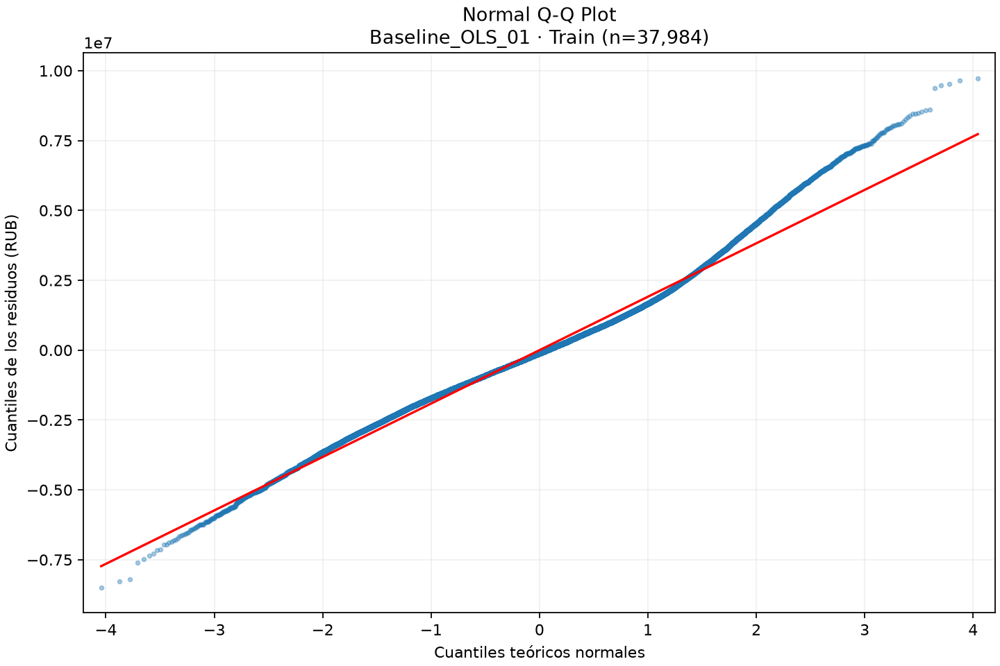

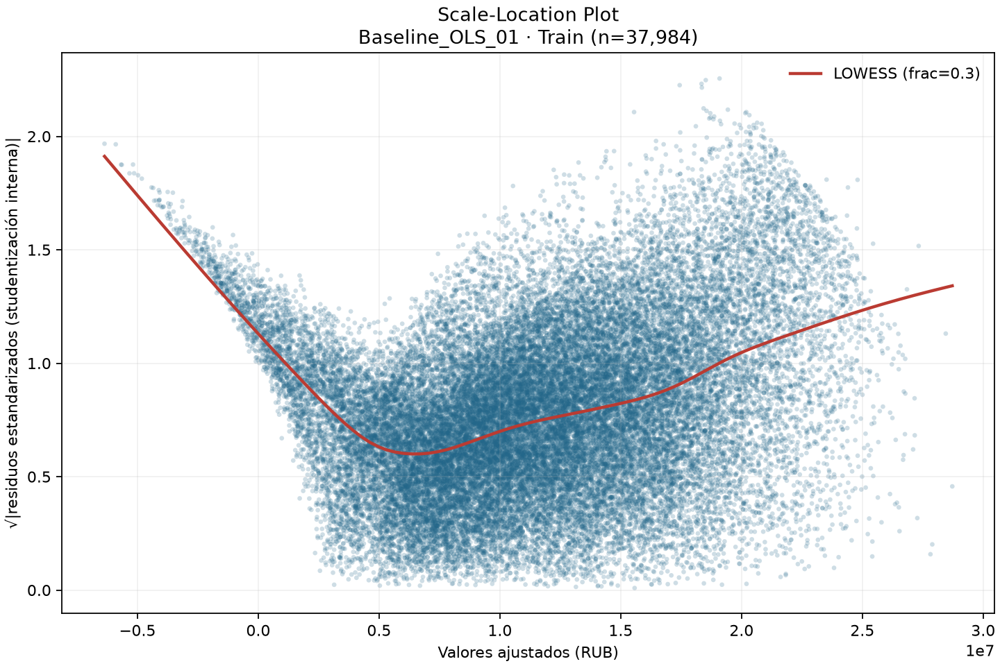

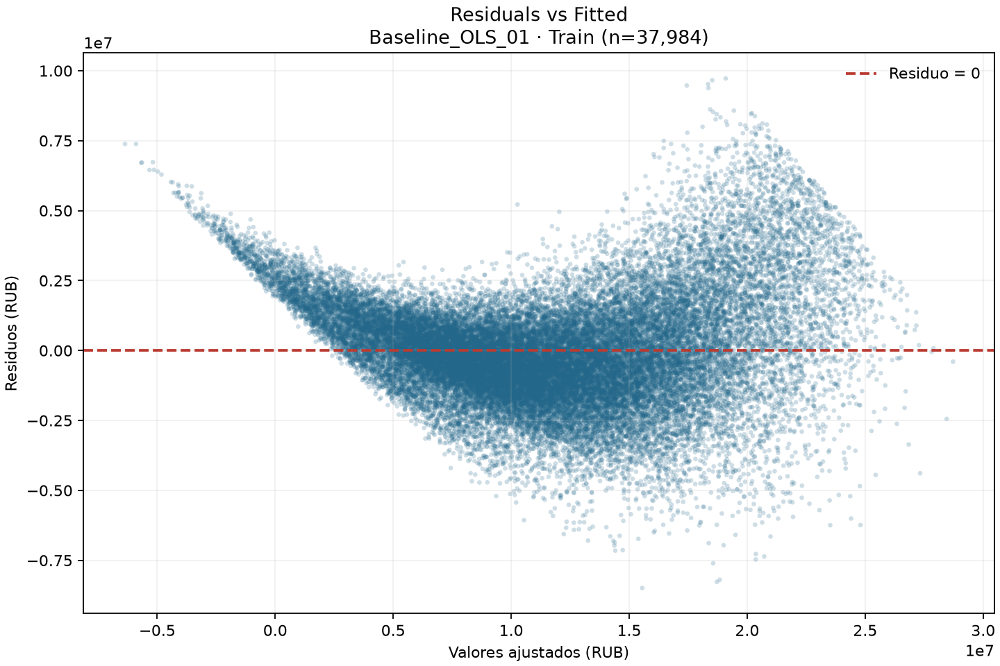

In [8]:
with sesion.paso():
    import json
    import numpy as np
    from IPython.display import Image, display
    from statsmodels.regression.linear_model import OLSResults
    from scripts import diagnosticos_residuales as dr
    salida_residuos = salida
    registro_residuos = registro
    metricas_antes_residuos = json.loads((salida_residuos / "metricas.json").read_text(encoding="utf-8"))
    ruta_modelo_residuos = salida_residuos / "modelo_statsmodels.pkl"
    huella_modelo_antes = b.sha256(ruta_modelo_residuos)
    modelo_residuos = OLSResults.load(ruta_modelo_residuos)
    X_residuos, y_residuos, contexto_residuos = b.cargar_train(base)
    diseno_residuos = b.sm.add_constant(X_residuos, has_constant="add")
    ajustados_residuos, residuos_train, estandarizados_train = dr.residuos_train(modelo_residuos, diseno_residuos, y_residuos)
    np.testing.assert_allclose(np.mean(residuos_train**2), metricas_antes_residuos["train_mse"], rtol=1e-12)
    np.testing.assert_allclose(np.sum(residuos_train**2), metricas_antes_residuos["train_rss"], rtol=1e-12)

    rutas_residuos = dr.generar_diagnosticos_residuales(
        modelo_residuos, diseno_residuos, y_residuos,
        nombre_run=registro_residuos["run_name"],
        carpeta=salida_residuos / "diagnosticos_residuales",
        unidad_objetivo=contexto_residuos["unidad"],
    )
    assert len(residuos_train) == contexto_residuos["n_train"] == 37984
    assert b.sha256(ruta_modelo_residuos) == huella_modelo_antes
    assert b.sha256(base / contexto_residuos["csv"]) == contexto_residuos["dataset_sha256"]
    for nombre in dr.ARCHIVOS:
        display(Image(filename=str(rutas_residuos[nombre])))
    print("Tres gráficos generados con todas las filas de Train; modelo y CSV intactos.")


### Registro en el mismo Run

Se agregan exclusivamente los tres PNG bajo `diagnosticos_residuales`, en el Run guardado en `registro_dagshub.json`. Se comprueba su descarga mediante SHA-256 y se verifica que estado, métricas y parámetros del Run se mantengan. No se crea otro Run.


In [9]:
with sesion.paso():
    cliente_residuos = b.conectar(raiz)
    run_antes_residuos = cliente_residuos.get_run(registro_residuos["run_id"])
    assert run_antes_residuos.info.experiment_id == registro_residuos["experiment_id"]
    assert run_antes_residuos.info.status == "FINISHED"
    assert run_antes_residuos.data.tags["dataset_sha256"] == contexto_residuos["dataset_sha256"]
    artefactos_residuos = dr.registrar_diagnosticos_residuales(
        cliente_residuos, registro_residuos["run_id"],
        salida_residuos / "diagnosticos_residuales",
        nombre_run=registro_residuos["run_name"],
    )
    assert b.sha256(ruta_modelo_residuos) == huella_modelo_antes
    assert b.sha256(base / contexto_residuos["csv"]) == contexto_residuos["dataset_sha256"]
    print("Run existente:", registro_residuos["run_id"], "— FINISHED")
    print("Artefactos verificados:", *artefactos_residuos, sep="\n")
    display(Markdown(f"[Abrir diagnósticos de {registro_residuos['run_name']}]({registro_residuos['url']})"))


Run existente: 43e383e9b91d43efbdeda5ec1ec28f71 — FINISHED
Artefactos verificados:
diagnosticos_residuales/qq_plot.png
diagnosticos_residuales/scale_location.png
diagnosticos_residuales/residuals_vs_fitted.png


[Abrir diagnósticos de Baseline_OLS_01](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/43e383e9b91d43efbdeda5ec1ec28f71)

Fin de la etapa Baseline_OLS_01 y su diagnóstico gráfico. La siguiente sección evalúa exclusivamente la transformación del objetivo.


# Experimento 02 — ln(price_rub)

Run **OLS_02_Log_Target**, dentro de **Modelos Propiedades_Usadas**. Se adopta el nombre exacto de la sección de registro de las instrucciones; la mención a OLS_03 en el ejemplo de tabla no modifica ese identificador.

Se aísla un único cambio: `ln(price_rub)`. Se mantienen todas las filas, las 177 predictoras (incluida `to_center_km`), el intercepto, el solver y el CSV de la baseline. No se consulta Test, no se vuelve a transformar X y no se aplica corrección de sesgo al invertir las predicciones. Toda evaluación es dentro de Train; no representa rendimiento fuera de muestra.


In [10]:
with sesion.paso():
    NOMBRE_LOG = "OLS_02_Log_Target"
    salida_log = sesion.carpeta("ols_02_log_target")
    salida_log.mkdir(exist_ok=True)
    referencia_log = cliente.get_run(registro["run_id"])
    assert referencia_log.info.status == "FINISHED"
    assert referencia_log.data.tags["mlflow.runName"] == "Baseline_OLS_01"
    assert referencia_log.info.experiment_id == cliente.get_experiment_by_name(b.EXPERIMENTO).experiment_id
    baseline_log = {"run_id": referencia_log.info.run_id, "experiment_id": referencia_log.info.experiment_id,
        "run_name": "Baseline_OLS_01", "status": referencia_log.info.status,
        "metrics": referencia_log.data.metrics, "params": referencia_log.data.params,
        "dataset_sha256": referencia_log.data.tags["dataset_sha256"], "url": registro["url"],
        "origen": "MLflow get_run y download_artifacts; baseline no reentrenada"}
    b.guardar_json(salida_log / "baseline_mlflow.json", baseline_log)
    carpeta_baseline_log = salida_log / "comparacion_baseline"
    carpeta_baseline_log.mkdir(exist_ok=True)
    contexto_baseline_log = json.loads(Path(cliente.download_artifacts(
        referencia_log.info.run_id, "contexto.json", str(carpeta_baseline_log))).read_text(encoding="utf-8"))
    rutas_baseline_log = {}
    for nombre in dr.ARCHIVOS:
        rutas_baseline_log[nombre] = Path(cliente.download_artifacts(referencia_log.info.run_id, "diagnosticos_residuales/" + nombre, str(carpeta_baseline_log)))

    X_log, y_precio_log, contexto_original_log = b.cargar_train(base)
    y_precio_intacto_log = y_precio_log.copy()
    assert (y_precio_log > 0).all()
    assert list(X_log.columns) == contexto_baseline_log["predictoras"]
    assert "to_center_km" in X_log.columns
    assert contexto_original_log["dataset_sha256"] == baseline_log["dataset_sha256"]
    assert len(y_precio_log) == baseline_log["metrics"]["train_n_obs"]
    contexto_log = {**contexto_original_log, "transformacion_objetivo": "ln", "unidad": "ln(RUB)",
        "unidad_original": "RUB", "prediccion_original": "exp(prediccion_log)", "correccion_sesgo": "ninguna",
        "baseline_run_id": referencia_log.info.run_id, "nombre_run": NOMBRE_LOG}
    print("Contrato validado:", len(y_precio_log), "filas;", X_log.shape[1], "predictoras; to_center_km incluida.")
    print("Referencia recuperada de MLflow:", referencia_log.info.run_id)


Contrato validado: 37984 filas; 177 predictoras; to_center_km incluida.
Referencia recuperada de MLflow: 43e383e9b91d43efbdeda5ec1ec28f71


## 7. Ajuste OLS con el objetivo logarítmico

Se usa una nueva Serie para el logaritmo natural; el precio original permanece intacto. La función de ajuste es la misma de la baseline.


In [11]:
with sesion.paso():
    y_ln_log = np.log(y_precio_log).rename("ln_price_rub")
    modelo_log, diseno_log = b.ajustar(X_log, y_ln_log)
    assert list(diseno_log.columns) == ["const"] + contexto_baseline_log["predictoras"]
    assert int(modelo_log.nobs) == len(y_precio_log)
    b.pd.testing.assert_series_equal(y_precio_log, y_precio_intacto_log)
    print(modelo_log.summary().as_text())


                            OLS Regression Results                            
Dep. Variable:           ln_price_rub   R-squared:                       0.956
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     4607.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:03:48   Log-Likelihood:                 27469.
No. Observations:               37984   AIC:                        -5.458e+04
Df Residuals:                   37806   BIC:                        -5.306e+04
Df Model:                         177                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

## 8. Evaluación con escalas separadas

Se reutiliza `diagnosticar` con el precio original como argumento adicional. El sufijo `_log` identifica las métricas del ajuste y de sus residuos en ln(RUB). El sufijo `_original` identifica la evaluación sobre precios mediante `exp(predicción log)`. VIF, Condition Number, rango y dimensiones corresponden al mismo diseño X.

AIC/BIC conservan la convención de statsmodels, con `k = rango del diseño`, pero ahora su likelihood está en ln(RUB). No se comparan directamente con AIC/BIC, R² o RSS nativos de la baseline en RUB. El R² ajustado sobre precios se conserva como medida descriptiva de Train, no como el R² ajustado del OLS logarítmico. MAPE se informa en porcentaje sobre precios originales.

La inversa exponencial puede subestimar el precio esperado: `exp(E[ln(precio)|X])` no equivale en general a `E[precio|X]`. Este experimento no aplica Duan ni otra corrección.


In [12]:
with sesion.paso():
    metricas_log, invalidas_log, vif_log, notas_log = b.diagnosticar(
        modelo_log, diseno_log, y_ln_log, y_original=y_precio_log)
    assert np.isfinite(list(metricas_log.values())).all()
    assert metricas_log["train_n_obs"] == len(y_precio_log)
    np.testing.assert_allclose(metricas_log["train_vif_max"], baseline_log["metrics"]["train_vif_max"], rtol=1e-10)
    np.testing.assert_allclose(metricas_log["train_condition_number"], baseline_log["metrics"]["train_condition_number"], rtol=1e-10)
    display(Markdown(b.tabla_resultados(metricas_log, invalidas_log, notas_log, nombre_run=NOMBRE_LOG)))
    print("Métricas numéricas válidas:", len(metricas_log))


Métricas numéricas válidas: 42


| Métrica | OLS_02_Log_Target | Unidad / Observación |
|---|---|---|
| R² (ln(RUB)) | 0.955694187914 | Train; ajuste log |
| R² ajustado (ln(RUB)) | 0.955486757116 | Train; ajuste log |
| MAE (ln(RUB)) | 0.0933372242985 | ln(RUB) |
| RMSE (ln(RUB)) | 0.117406144956 | ln(RUB) |
| RSS (ln(RUB)) | 523.579161946 | ln(RUB)² |
| MSE (ln(RUB)) | 0.0137842028735 | ln(RUB)² |
| AIC (ln(RUB)) | -54582.3481458 | Train; likelihood ln(RUB); k=rank |
| BIC (ln(RUB)) | -53061.3523329 | Train; likelihood ln(RUB); k=rank |
| F-statistic (ln(RUB)) | 4607.29167676 | Train; ajuste log |
| Probabilidad F-statistic (ln(RUB)) | 0 | Train; ajuste log |
| n_obs | 37984 | Train |
| n_predictors | 177 | Train |
| n_parameters_effective | 178 | Train |
| n_coefficients | 178 | Train |
| df_model | 177 | Train |
| df_resid | 37806 | Train |
| log_likelihood (ln(RUB)) | 27469.1740729 | Train; ajuste log |
| Durbin-Watson (ln(RUB)) | 1.79418181535 | Train; ajuste log |
| n_coefficients_p_gt_005 (ln(RUB)) | 26 | Train; ajuste log |
| n_coefficients_p_undefined (ln(RUB)) | 0 | Train; ajuste log |
| condition_number | 19159.1660483 | Train |
| rank_deficiency | 0 | Train |
| jarque_bera (ln(RUB)) | 183.542393045 | Train; ajuste log |
| jarque_bera_pvalue (ln(RUB)) | 1.39404166021e-40 | Train; ajuste log |
| skewness (ln(RUB)) | -0.166356738106 | Train; ajuste log |
| kurtosis (ln(RUB)) | 3.07260911624 | Train; ajuste log |
| omnibus (ln(RUB)) | 180.778930354 | Train; ajuste log |
| omnibus_pvalue (ln(RUB)) | 5.5507804677e-40 | Train; ajuste log |
| VIF máximo | 102.584323807 | Sin intercepto |
| vif_infinite_count | 0 | Train |
| vif_undefined_count | 0 | Train |
| bp_lm (ln(RUB)) | 1195.72279526 | Train; ajuste log |
| bp_lm_pvalue (ln(RUB)) | 1.19611077672e-150 | Train; ajuste log |
| bp_f (ln(RUB)) | 6.94238224449 | Train; ajuste log |
| bp_f_pvalue (ln(RUB)) | 1.11625003601e-153 | Train; ajuste log |
| R² (precio original) | 0.927524646297 | Train |
| R² ajustado (precio original) | 0.927185331436 | Train |
| MAE (precio original) | 1093408.72367 | RUB |
| RMSE (precio original) | 1575798.35333 | RUB |
| MAPE (precio original) | 9.40748518507 | % |
| RSS (precio original) | 9.43196068667e+16 | RUB² |
| MSE (precio original) | 2.48314045037e+12 | RUB² |

## 9. Exportación y comparación predictiva con la baseline

Se reutiliza la exportación: modelo sin matrices de entrenamiento, resumen completo, coeficientes, métricas, VIF, contrato de inferencia, versiones, código y tres PNG de residuos logarítmicos. La inversa documentada es exclusivamente `exp`.

La comparación utiliza las métricas de la baseline recuperadas de MLflow. Las diferencias se calculan únicamente para R², MAE, MSE y RMSE evaluados sobre el mismo precio original y las mismas filas. La segunda sección conserva las estadísticas del modelo logarítmico sin diferencias entre escalas.


In [13]:
with sesion.paso():
    salida_log = b.exportar(base, modelo_log, diseno_log, y_ln_log, contexto_log,
        metricas_log, invalidas_log, vif_log, notas_log,
        nombre_run=NOMBRE_LOG, carpeta_salida=salida_log)
    filas_comparacion_log = []
    for etiqueta, clave in [("R² (escala original)", "r2"), ("MAE (RUB)", "mae"),
                            ("MSE (RUB²)", "mse"), ("RMSE (RUB)", "rmse")]:
        anterior = baseline_log["metrics"]["train_" + clave]
        nuevo = metricas_log["train_" + clave + "_original"]
        filas_comparacion_log.append({"Métrica": etiqueta, "Baseline_OLS_01": format(anterior, ".12g"),
            NOMBRE_LOG: format(nuevo, ".12g"), "Diferencia": format(nuevo - anterior, ".12g")})
    comparacion_log_md = ("# Comparación predictiva sobre precios originales — Train\n\n"
        + f"Baseline recuperada de MLflow: {baseline_log['run_id']}. Mismas filas y predictoras.\n\n"
        + b.tabla_markdown(b.pd.DataFrame(filas_comparacion_log))
        + "\n\nDiferencia = OLS_02_Log_Target − Baseline_OLS_01. Predicción nueva = exp(predicción log), sin corrección.\n\n"
        + "## Estadísticas del modelo en ln(RUB), sin diferencias entre escalas\n\n"
        + b.tabla_resultados({k:v for k,v in metricas_log.items() if not k.endswith("_original")},
            invalidas_log, notas_log, nombre_run=NOMBRE_LOG)
        + "\n\nAIC/BIC, R² y RSS nativos log no son directamente comparables con las métricas nativas en RUB de la baseline.\n")
    (salida_log / "comparacion_baseline.md").write_text(comparacion_log_md, encoding="utf-8")
    recuperado_log = OLSResults.load(salida_log / "modelo_statsmodels.pkl")
    np.testing.assert_allclose(np.exp(recuperado_log.predict(diseno_log)),
        np.exp(modelo_log.predict(diseno_log)), rtol=1e-12)
    b.pd.testing.assert_series_equal(y_precio_log, y_precio_intacto_log)
    assert b.sha256(base / contexto_log["csv"]) == contexto_log["dataset_sha256"]
    display(Markdown(comparacion_log_md))


# Comparación predictiva sobre precios originales — Train

Baseline recuperada de MLflow: 43e383e9b91d43efbdeda5ec1ec28f71. Mismas filas y predictoras.

| Métrica | Baseline_OLS_01 | OLS_02_Log_Target | Diferencia |
|---|---|---|---|
| R² (escala original) | 0.893313416689 | 0.927524646297 | 0.0342112296074 |
| MAE (RUB) | 1442336.50357 | 1093408.72367 | -348927.779896 |
| MSE (RUB²) | 3.65528082297e+12 | 2.48314045037e+12 | -1.17214037261e+12 |
| RMSE (RUB) | 1911878.87246 | 1575798.35333 | -336080.519131 |

Diferencia = OLS_02_Log_Target − Baseline_OLS_01. Predicción nueva = exp(predicción log), sin corrección.

## Estadísticas del modelo en ln(RUB), sin diferencias entre escalas

| Métrica | OLS_02_Log_Target | Unidad / Observación |
|---|---|---|
| R² (ln(RUB)) | 0.955694187914 | Train; ajuste log |
| R² ajustado (ln(RUB)) | 0.955486757116 | Train; ajuste log |
| MAE (ln(RUB)) | 0.0933372242985 | ln(RUB) |
| RMSE (ln(RUB)) | 0.117406144956 | ln(RUB) |
| RSS (ln(RUB)) | 523.579161946 | ln(RUB)² |
| MSE (ln(RUB)) | 0.0137842028735 | ln(RUB)² |
| AIC (ln(RUB)) | -54582.3481458 | Train; likelihood ln(RUB); k=rank |
| BIC (ln(RUB)) | -53061.3523329 | Train; likelihood ln(RUB); k=rank |
| F-statistic (ln(RUB)) | 4607.29167676 | Train; ajuste log |
| Probabilidad F-statistic (ln(RUB)) | 0 | Train; ajuste log |
| n_obs | 37984 | Train |
| n_predictors | 177 | Train |
| n_parameters_effective | 178 | Train |
| n_coefficients | 178 | Train |
| df_model | 177 | Train |
| df_resid | 37806 | Train |
| log_likelihood (ln(RUB)) | 27469.1740729 | Train; ajuste log |
| Durbin-Watson (ln(RUB)) | 1.79418181535 | Train; ajuste log |
| n_coefficients_p_gt_005 (ln(RUB)) | 26 | Train; ajuste log |
| n_coefficients_p_undefined (ln(RUB)) | 0 | Train; ajuste log |
| condition_number | 19159.1660483 | Train |
| rank_deficiency | 0 | Train |
| jarque_bera (ln(RUB)) | 183.542393045 | Train; ajuste log |
| jarque_bera_pvalue (ln(RUB)) | 1.39404166021e-40 | Train; ajuste log |
| skewness (ln(RUB)) | -0.166356738106 | Train; ajuste log |
| kurtosis (ln(RUB)) | 3.07260911624 | Train; ajuste log |
| omnibus (ln(RUB)) | 180.778930354 | Train; ajuste log |
| omnibus_pvalue (ln(RUB)) | 5.5507804677e-40 | Train; ajuste log |
| VIF máximo | 102.584323807 | Sin intercepto |
| vif_infinite_count | 0 | Train |
| vif_undefined_count | 0 | Train |
| bp_lm (ln(RUB)) | 1195.72279526 | Train; ajuste log |
| bp_lm_pvalue (ln(RUB)) | 1.19611077672e-150 | Train; ajuste log |
| bp_f (ln(RUB)) | 6.94238224449 | Train; ajuste log |
| bp_f_pvalue (ln(RUB)) | 1.11625003601e-153 | Train; ajuste log |

AIC/BIC, R² y RSS nativos log no son directamente comparables con las métricas nativas en RUB de la baseline.


## 10. Comparación visual de residuos

Columna izquierda: baseline en RUB, descargada de su Run. Columna derecha: nuevo OLS en ln(RUB). Se comparan las formas y los patrones, no las magnitudes de ejes que tienen distinta escala. Scale-Location utiliza la misma definición de residuos estandarizados y el mismo suavizado LOWESS en ambos casos.


Baseline_OLS_01 · RUB,OLS_02_Log_Target · ln(RUB)
,
,
,

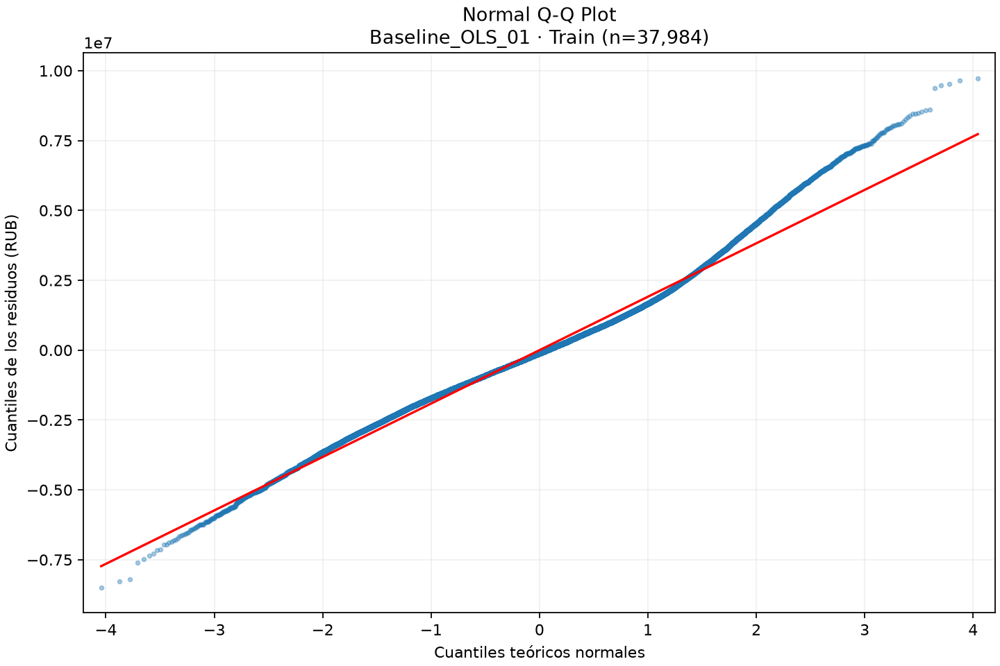
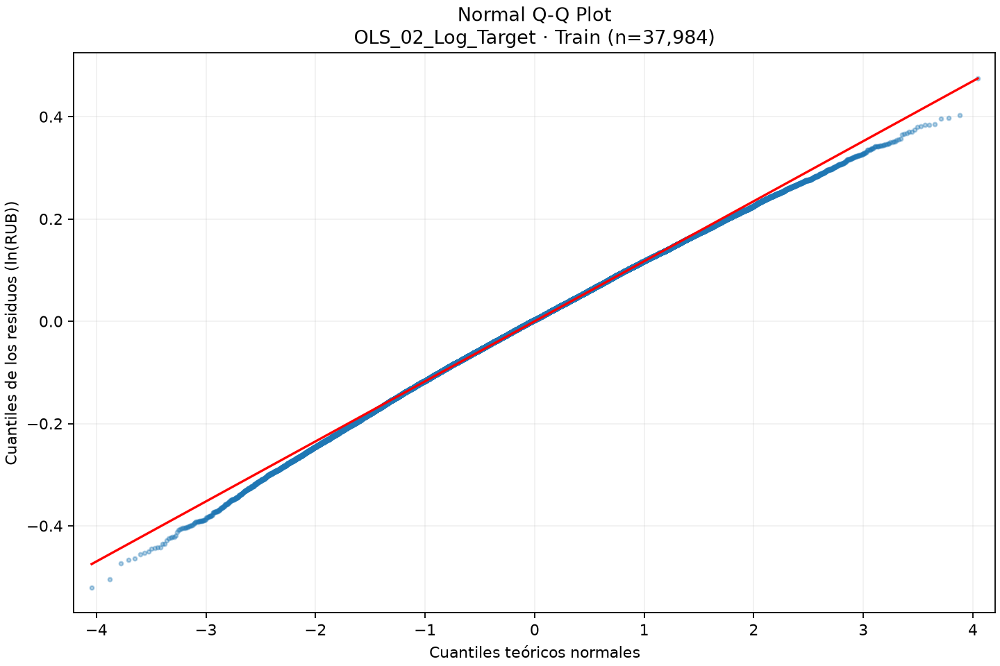
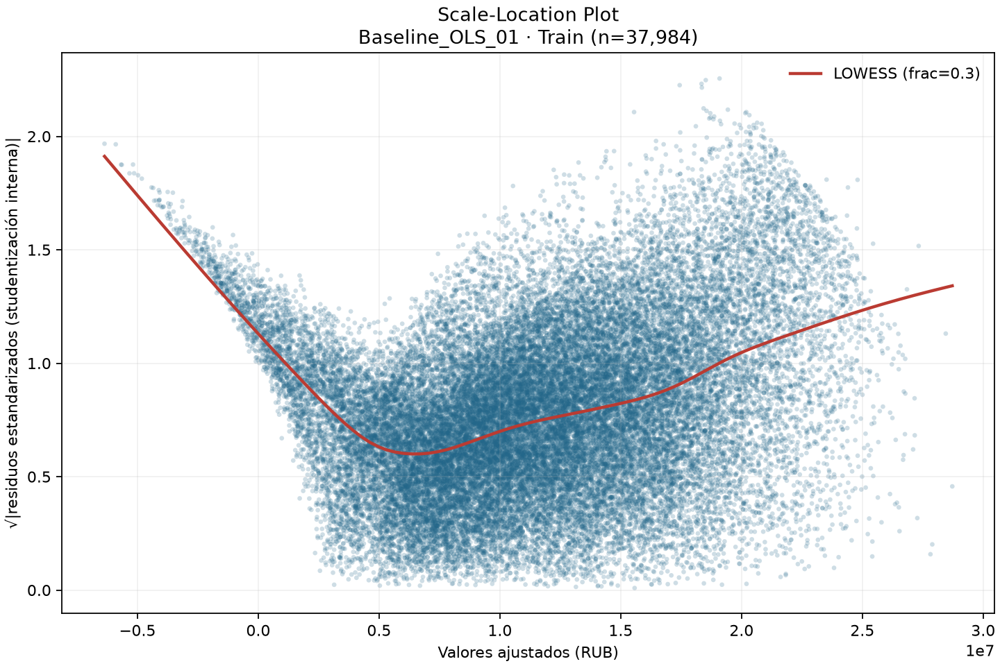
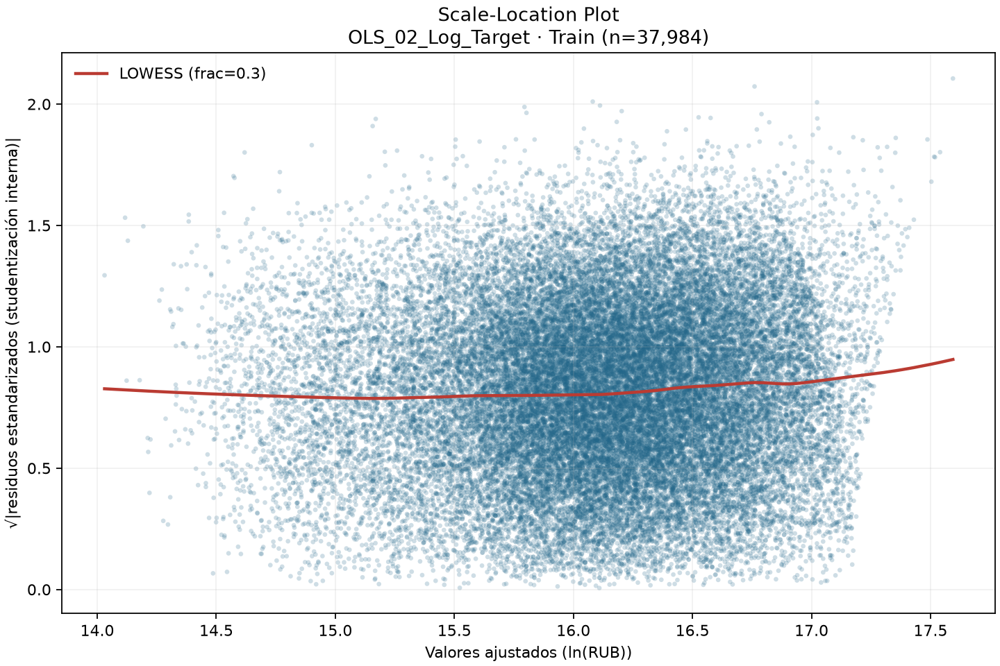
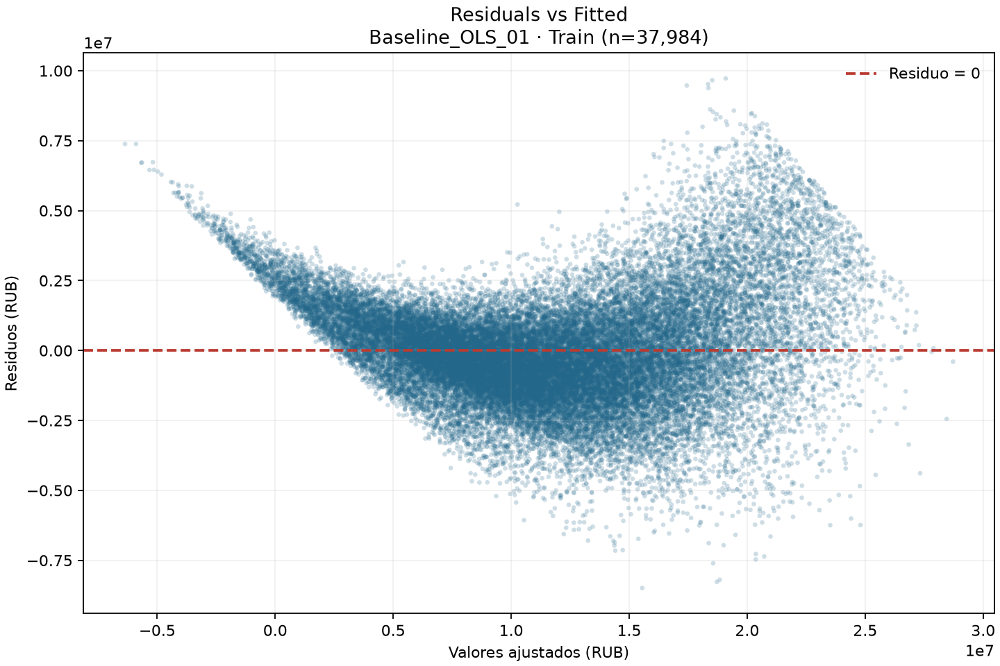
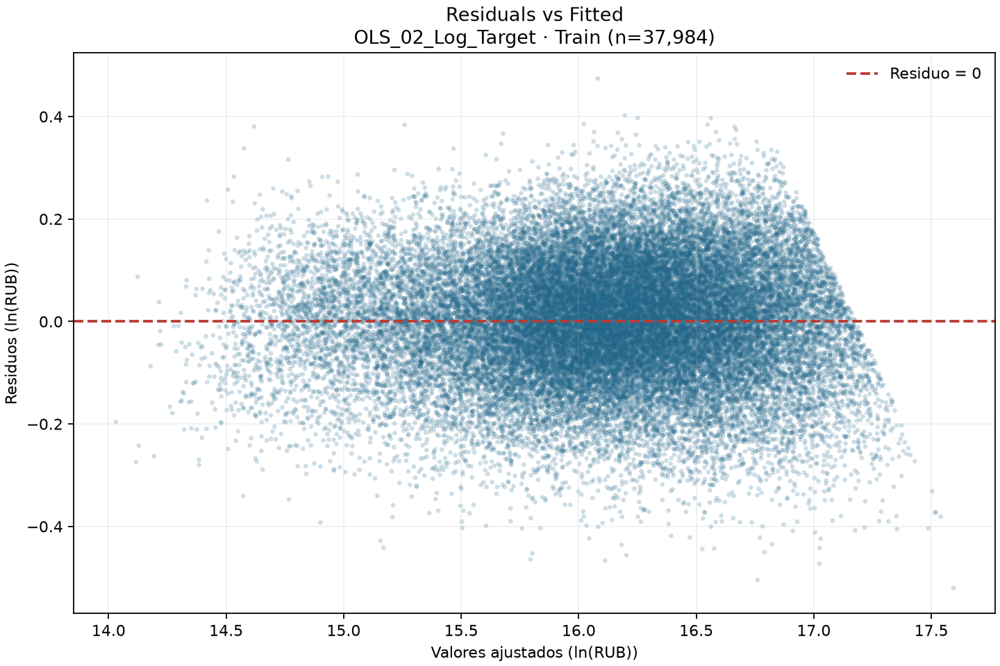

In [14]:
with sesion.paso():
    from IPython.display import HTML
    comparacion_graficos_log = dr.comparar_diagnosticos_residuales(
        rutas_baseline_log, salida_log / "diagnosticos_residuales",
        nombre_referencia="Baseline_OLS_01", nombre_nuevo=NOMBRE_LOG,
        unidad_referencia="RUB", unidad_nuevo="ln(RUB)",
        archivo_html=salida_log / "comparacion_residuos.html")
    display(HTML(comparacion_graficos_log))


## 11. Interpretación acotada a este experimento

La comparación gráfica se refiere a formas en las respectivas escalas de ajuste. La comparación predictiva utiliza únicamente las métricas en RUB de Train. No se elige un modelo óptimo ni se modifican observaciones o predictores.


In [15]:
with sesion.paso():
    reduccion_mae_log = 100 * (1 - metricas_log["train_mae_original"] / baseline_log["metrics"]["train_mae"])
    reduccion_rmse_log = 100 * (1 - metricas_log["train_rmse_original"] / baseline_log["metrics"]["train_rmse"])
    interpretacion_log = f"""# Interpretación de OLS_02_Log_Target — Train

    El QQ-Plot del ajuste logarítmico queda más próximo a la recta normal, aunque conserva desviaciones en las colas. La asimetría cambia de {baseline_log['metrics']['train_skewness']:.4f} a {metricas_log['train_skewness_log']:.4f} y la curtosis de {baseline_log['metrics']['train_kurtosis']:.4f} a {metricas_log['train_kurtosis_log']:.4f}. Jarque-Bera pasa de {baseline_log['metrics']['train_jarque_bera']:.2f} a {metricas_log['train_jarque_bera_log']:.2f}, pero su p-value log ({metricas_log['train_jarque_bera_pvalue_log']:.3e}) sigue rechazando normalidad al 5 %. La mejora visual y de los momentos no demuestra normalidad exacta.

    Scale-Location presenta una curva LOWESS más horizontal y una dispersión más uniforme que la baseline. Persiste un aumento de la dispersión hacia los mayores ajustados. Residuos vs ajustados también conserva estructura en el extremo superior; los patrones no desaparecen completamente.

    Breusch-Pagan robusto (Koenker) devuelve LM={metricas_log['train_bp_lm_log']:.2f}, p={metricas_log['train_bp_lm_pvalue_log']:.3e}; en la baseline LM={baseline_log['metrics']['train_bp_lm']:.2f}, con p devuelto como {baseline_log['metrics']['train_bp_lm_pvalue']:.3g} (posible subdesbordamiento numérico). Ambos rechazan homocedasticidad. El menor estadístico del nuevo ajuste no permite afirmar que la heterocedasticidad esté resuelta.

    En precios originales, sin corrección de sesgo, MAE disminuye {reduccion_mae_log:.2f} % y RMSE {reduccion_rmse_log:.2f} %. El R² comparable en RUB pasa de {baseline_log['metrics']['train_r2']:.6f} a {metricas_log['train_r2_original']:.6f}; la tabla anterior conserva también MSE y sus diferencias. AIC/BIC, RSS y R² nativos log se informan por separado y no se comparan directamente con sus equivalentes nativos en RUB.

    No todos los diagnósticos mejoran: Durbin-Watson cambia de {baseline_log['metrics']['train_durbin_watson']:.4f} a {metricas_log['train_durbin_watson_log']:.4f}, alejándose de 2; depende del orden de filas del CSV y no constituye por sí solo una prueba temporal de este panel. La inversa exponencial mantiene el posible sesgo al estimar el precio esperado.

    La menor desviación de normalidad, la dispersión más uniforme y los menores errores de Train justifican considerar ln(price_rub) en modelos posteriores. Este resultado no establece superioridad fuera de muestra ni una decisión definitiva de modelo óptimo: no se utilizó Test. Se mantienen todas las filas y las 177 predictoras, incluida to_center_km.
    """
    (salida_log / "interpretacion.md").write_text(interpretacion_log, encoding="utf-8")
    display(Markdown(interpretacion_log))


# Interpretación de OLS_02_Log_Target — Train

El QQ-Plot del ajuste logarítmico queda más próximo a la recta normal, aunque conserva desviaciones en las colas. La asimetría cambia de 0.4532 a -0.1664 y la curtosis de 4.2729 a 3.0726. Jarque-Bera pasa de 3864.73 a 183.54, pero su p-value log (1.394e-40) sigue rechazando normalidad al 5 %. La mejora visual y de los momentos no demuestra normalidad exacta.

Scale-Location presenta una curva LOWESS más horizontal y una dispersión más uniforme que la baseline. Persiste un aumento de la dispersión hacia los mayores ajustados. Residuos vs ajustados también conserva estructura en el extremo superior; los patrones no desaparecen completamente.

Breusch-Pagan robusto (Koenker) devuelve LM=1195.72, p=1.196e-150; en la baseline LM=5743.81, con p devuelto como 0 (posible subdesbordamiento numérico). Ambos rechazan homocedasticidad. El menor estadístico del nuevo ajuste no permite afirmar que la heterocedasticidad esté resuelta.

En precios originales, sin corrección de sesgo, MAE disminuye 24.19 % y RMSE 17.58 %. El R² comparable en RUB pasa de 0.893313 a 0.927525; la tabla anterior conserva también MSE y sus diferencias. AIC/BIC, RSS y R² nativos log se informan por separado y no se comparan directamente con sus equivalentes nativos en RUB.

No todos los diagnósticos mejoran: Durbin-Watson cambia de 1.9220 a 1.7942, alejándose de 2; depende del orden de filas del CSV y no constituye por sí solo una prueba temporal de este panel. La inversa exponencial mantiene el posible sesgo al estimar el precio esperado.

La menor desviación de normalidad, la dispersión más uniforme y los menores errores de Train justifican considerar ln(price_rub) en modelos posteriores. Este resultado no establece superioridad fuera de muestra ni una decisión definitiva de modelo óptimo: no se utilizó Test. Se mantienen todas las filas y las 177 predictoras, incluida to_center_km.


## 12. Registro de OLS_02_Log_Target y verificación final

Se reutiliza el registro del experimento existente. Todas las métricas finitas se envían individualmente a Metrics con nombres que identifican su escala. Los tres PNG se conservan bajo `diagnosticos_residuales`; se agregan las tablas Markdown, la comparación visual y las referencias recuperadas de la baseline. Se descargan y comparan los artefactos mediante SHA-256. La baseline se consulta nuevamente para comprobar que permanece intacta.


In [16]:
with sesion.paso():
    registro_log = b.registrar(cliente, salida_log, contexto_log, metricas_log, nombre_run=NOMBRE_LOG)
    remoto_log = cliente.get_run(registro_log["run_id"])
    assert remoto_log.info.status == "FINISHED" and remoto_log.info.experiment_id == referencia_log.info.experiment_id
    assert remoto_log.data.params["target_transform"] == "ln(Target)"
    assert remoto_log.data.params["inverse_transform"] == "exp" and remoto_log.data.params["bias_correction"] == "none"
    assert remoto_log.data.params["n_predictors"] == "177" and remoto_log.data.params["n_train"] == "37984"
    baseline_despues_log = cliente.get_run(baseline_log["run_id"])
    assert baseline_despues_log.info.status == baseline_log["status"]
    assert baseline_despues_log.data.metrics == baseline_log["metrics"]
    assert baseline_despues_log.data.params == baseline_log["params"]
    assert b.sha256(base / contexto_log["csv"]) == contexto_log["dataset_sha256"]
    print("Run:", registro_log["run_id"], "— FINISHED")
    print("Verificados:", len(metricas_log), "métricas; parámetros; modelo; tablas; gráficos y todos los artefactos.")
    print("Train intacto; Test no utilizado; baseline sin cambios; to_center_km conservada. Fin del experimento.")
    display(Markdown(f"[Abrir {NOMBRE_LOG} en DagsHub]({registro_log['url']})"))
    display(Markdown(comparacion_log_md))


🏃 View run OLS_02_Log_Target at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/2dfd0a0d8d7a41818305f1137704b26e
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5
Run: 2dfd0a0d8d7a41818305f1137704b26e — FINISHED
Verificados: 42 métricas; parámetros; modelo; tablas; gráficos y todos los artefactos.
Train intacto; Test no utilizado; baseline sin cambios; to_center_km conservada. Fin del experimento.


[Abrir OLS_02_Log_Target en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/2dfd0a0d8d7a41818305f1137704b26e)

# Comparación predictiva sobre precios originales — Train

Baseline recuperada de MLflow: 43e383e9b91d43efbdeda5ec1ec28f71. Mismas filas y predictoras.

| Métrica | Baseline_OLS_01 | OLS_02_Log_Target | Diferencia |
|---|---|---|---|
| R² (escala original) | 0.893313416689 | 0.927524646297 | 0.0342112296074 |
| MAE (RUB) | 1442336.50357 | 1093408.72367 | -348927.779896 |
| MSE (RUB²) | 3.65528082297e+12 | 2.48314045037e+12 | -1.17214037261e+12 |
| RMSE (RUB) | 1911878.87246 | 1575798.35333 | -336080.519131 |

Diferencia = OLS_02_Log_Target − Baseline_OLS_01. Predicción nueva = exp(predicción log), sin corrección.

## Estadísticas del modelo en ln(RUB), sin diferencias entre escalas

| Métrica | OLS_02_Log_Target | Unidad / Observación |
|---|---|---|
| R² (ln(RUB)) | 0.955694187914 | Train; ajuste log |
| R² ajustado (ln(RUB)) | 0.955486757116 | Train; ajuste log |
| MAE (ln(RUB)) | 0.0933372242985 | ln(RUB) |
| RMSE (ln(RUB)) | 0.117406144956 | ln(RUB) |
| RSS (ln(RUB)) | 523.579161946 | ln(RUB)² |
| MSE (ln(RUB)) | 0.0137842028735 | ln(RUB)² |
| AIC (ln(RUB)) | -54582.3481458 | Train; likelihood ln(RUB); k=rank |
| BIC (ln(RUB)) | -53061.3523329 | Train; likelihood ln(RUB); k=rank |
| F-statistic (ln(RUB)) | 4607.29167676 | Train; ajuste log |
| Probabilidad F-statistic (ln(RUB)) | 0 | Train; ajuste log |
| n_obs | 37984 | Train |
| n_predictors | 177 | Train |
| n_parameters_effective | 178 | Train |
| n_coefficients | 178 | Train |
| df_model | 177 | Train |
| df_resid | 37806 | Train |
| log_likelihood (ln(RUB)) | 27469.1740729 | Train; ajuste log |
| Durbin-Watson (ln(RUB)) | 1.79418181535 | Train; ajuste log |
| n_coefficients_p_gt_005 (ln(RUB)) | 26 | Train; ajuste log |
| n_coefficients_p_undefined (ln(RUB)) | 0 | Train; ajuste log |
| condition_number | 19159.1660483 | Train |
| rank_deficiency | 0 | Train |
| jarque_bera (ln(RUB)) | 183.542393045 | Train; ajuste log |
| jarque_bera_pvalue (ln(RUB)) | 1.39404166021e-40 | Train; ajuste log |
| skewness (ln(RUB)) | -0.166356738106 | Train; ajuste log |
| kurtosis (ln(RUB)) | 3.07260911624 | Train; ajuste log |
| omnibus (ln(RUB)) | 180.778930354 | Train; ajuste log |
| omnibus_pvalue (ln(RUB)) | 5.5507804677e-40 | Train; ajuste log |
| VIF máximo | 102.584323807 | Sin intercepto |
| vif_infinite_count | 0 | Train |
| vif_undefined_count | 0 | Train |
| bp_lm (ln(RUB)) | 1195.72279526 | Train; ajuste log |
| bp_lm_pvalue (ln(RUB)) | 1.19611077672e-150 | Train; ajuste log |
| bp_f (ln(RUB)) | 6.94238224449 | Train; ajuste log |
| bp_f_pvalue (ln(RUB)) | 1.11625003601e-153 | Train; ajuste log |

AIC/BIC, R² y RSS nativos log no son directamente comparables con las métricas nativas en RUB de la baseline.


Fin del Experimento 02. La siguiente sección evalúa únicamente la exclusión explícita de to_center_km manteniendo el objetivo logarítmico.


# Experimento 03 — OLS logarítmico sin to_center_km

Run **OLS_03_Log_Sin_to_center_km**, nombre exacto del apartado de registro. Referencia exclusiva: **OLS_02_Log_Target**. Se conserva `ln(price_rub)` como objetivo para esta etapa y los modelos posteriores.

Único cambio: excluir `to_center_km` del DataFrame X ya cargado. Se conservan las mismas 37.984 filas, las otras 176 predictoras, intercepto, configuración de OLS y predicción en RUB mediante `exp`, sin corrección de sesgo. No se consulta Test, no se transforman otras variables y no se realiza selección automática.


In [17]:
with sesion.paso():
    NOMBRE_03 = "OLS_03_Log_Sin_to_center_km"
    datos_03 = b.preparar_ablacion(cliente, base, X_log, y_ln_log, y_precio_log,
        registro_referencia=registro_log, variable="to_center_km", nombre_run=NOMBRE_03,
        carpeta_salida=sesion.carpeta("ols_03_log_sin_to_center_km"))
    salida_03, X_03, contexto_03 = datos_03["salida"], datos_03["X"], datos_03["contexto"]
    referencia_03, metricas_referencia_03 = datos_03["referencia"], datos_03["metricas_referencia"]
    archivos_referencia_03, modelo_completo_03 = datos_03["archivos"], datos_03["modelo_referencia"]
    print("Referencia recuperada de MLflow:", referencia_03.info.run_id)
    print("Mismas", len(X_03), "filas; 176 predictoras; única exclusión: to_center_km.")


Referencia recuperada de MLflow: 2dfd0a0d8d7a41818305f1137704b26e
Mismas 37984 filas; 176 predictoras; única exclusión: to_center_km.
VIF medio y conteos de referencia resumidos desde vif.csv; no se recalcula ni se reentrena OLS_02.


## 13. Ajuste y evaluación del modelo reducido

Se reutilizan las funciones de entrenamiento y diagnóstico. Las métricas conservan los nombres del Experimento 02; se agregan VIF promedio y conteos mayores a 5 y 10, siempre sin intercepto. Para la referencia, estos tres resúmenes se obtienen de su `vif.csv` descargado, sin recalcular regresiones auxiliares ni modificar el Run anterior.


In [18]:
with sesion.paso():
    modelo_03, diseno_03 = b.ajustar(X_03, y_ln_log)
    assert list(diseno_03.columns) == [c for c in modelo_completo_03.model.exog_names if c != "to_center_km"]
    b.pd.testing.assert_series_equal(y_precio_log, y_precio_intacto_log)
    print("Ajuste verificado:", int(modelo_03.nobs), "filas; rango", modelo_03.model.rank, "; intercepto explícito.")


Ajuste verificado: 37984 filas; rango 177 ; intercepto explícito.


## 14. Aporte incremental, significancia y modelos anidados

Los dos ajustes tienen idénticas filas, respuesta ln(RUB) y covarianza `nonrobust`, y el diseño reducido está anidado en el completo. AIC, BIC y las métricas logarítmicas son comparables con la misma convención `k = rango`.

El aporte incremental se define como `R²_completo − R²_reducido`; el R² parcial como `(RSS_reducido − RSS_completo) / RSS_reducido`. Las diferencias de las tablas utilizan el signo contrario cuando corresponde: **Δ = Experimento 03 − Experimento 02**.

El Experimento 02 rechazó homocedasticidad. Como advierte la documentación local de `statsmodels.RegressionResults.compare_f_test`, el F parcial clásico no es válido bajo heterocedasticidad o correlación no especificadas. Se conserva su estadístico **solo descriptivo** y se omite el p-value clásico. Los coeficientes, t y p-values originales se recuperan del modelo y del CSV registrado; su significancia nominal tiene la misma limitación.

Como diagnóstico complementario se calcula un Wald chi-cuadrado de 1 gl con covarianza HC3 del modelo completo ya registrado, sin reajustar ni cambiar coeficientes o predicciones. HC3 admite heterocedasticidad bajo independencia de filas; no corrige dependencia temporal o por grupos. Los cambios de significancia de las demás variables se describen con sus p-values `nonrobust`, sin convertirlos en reglas de selección.


In [19]:
with sesion.paso():
    resultado_03 = b.evaluar_ablacion(datos_03, modelo_03, diseno_03)
    metricas_03, invalidas_03, vif_03, notas_03 = (resultado_03[k] for k in ["metricas", "invalidas", "vif", "notas"])
    importancia_03, cambios_significancia_03 = resultado_03["importancia"], resultado_03["cambios"]
    comparacion_03_md = resultado_03["comparacion_md"]
    display(Markdown(comparacion_03_md))
    print("Cambios nominales de significancia:", importancia_03["n_significance_changes"], "; detalle completo en cambios_significancia.csv.")
    if importancia_03["n_significance_changes"]:
        display(cambios_significancia_03.loc[cambios_significancia_03["cambia"]].head(12))


Cambios nominales de significancia: 6 ; detalle completo en cambios_significancia.csv.


# Comparación exclusiva con OLS_02_Log_Target — Train

Referencia MLflow: 2dfd0a0d8d7a41818305f1137704b26e. Mismas filas, mismo objetivo ln(RUB), misma inversa exp sin corrección.

Δ = Experimento 03 − Experimento 02. VIF sin intercepto; media y conteos de OLS_02 derivados de su artefacto vif.csv.

| Métrica | OLS_02_Log_Target | OLS_03_Log_Sin_to_center_km | Diferencia |
|---|---|---|---|
| R² (ln(RUB)) | 0.955694187914 | 0.955388277995 | -0.000305909919117 |
| R² ajustado (ln(RUB)) | 0.955486757116 | 0.955180600499 | -0.000306156616895 |
| MAE (ln(RUB)) | 0.0933372242985 | 0.0936698768163 | 0.000332652517833 |
| RMSE (ln(RUB)) | 0.117406144956 | 0.11781076368 | 0.000404618724259 |
| RSS (ln(RUB)) | 523.579161946 | 527.194219464 | 3.61505751823 |
| MSE (ln(RUB)) | 0.0137842028735 | 0.013879376039 | 9.51731654967e-05 |
| AIC (ln(RUB)) | -54582.3481458 | -54322.9884864 | 259.3596594 |
| BIC (ln(RUB)) | -53061.3523329 | -52810.5375938 | 250.814739103 |
| F-statistic (ln(RUB)) | 4607.29167676 | 4600.34572177 | -6.94595499313 |
| Probabilidad F-statistic (ln(RUB)) | 0 | 0 | 0 |
| n_obs | 37984 | 37984 | 0 |
| n_predictors | 177 | 176 | -1 |
| n_parameters_effective | 178 | 177 | -1 |
| n_coefficients | 178 | 177 | -1 |
| df_model | 177 | 176 | -1 |
| df_resid | 37806 | 37807 | 1 |
| log_likelihood (ln(RUB)) | 27469.1740729 | 27338.4942432 | -130.6798297 |
| Durbin-Watson (ln(RUB)) | 1.79418181535 | 1.79682392767 | 0.00264211232534 |
| n_coefficients_p_gt_005 (ln(RUB)) | 26 | 22 | -4 |
| n_coefficients_p_undefined (ln(RUB)) | 0 | 0 | 0 |
| condition_number | 19159.1660483 | 14533.7195965 | -4625.44645177 |
| rank_deficiency | 0 | 0 | 0 |
| jarque_bera (ln(RUB)) | 183.542393045 | 179.17967428 | -4.36271876462 |
| jarque_bera_pvalue (ln(RUB)) | 1.39404166021e-40 | 1.23488949282e-39 | 1.0954853268e-39 |
| skewness (ln(RUB)) | -0.166356738106 | -0.163908965601 | 0.00244777250443 |
| kurtosis (ln(RUB)) | 3.07260911624 | 3.0758233672 | 0.00321425095787 |
| omnibus (ln(RUB)) | 180.778930354 | 176.476612361 | -4.30231799284 |
| omnibus_pvalue (ln(RUB)) | 5.5507804677e-40 | 4.7707925594e-39 | 4.21571451263e-39 |
| VIF máximo | 102.584323807 | 17.4312021082 | -85.1531216992 |
| VIF promedio | 3.66833820845 | 2.24384256672 | -1.42449564173 |
| Cantidad VIF > 5 | 18 | 4 | -14 |
| Cantidad VIF > 10 | 11 | 3 | -8 |
| vif_infinite_count | 0 | 0 | 0 |
| vif_undefined_count | 0 | 0 | 0 |
| bp_lm (ln(RUB)) | 1195.72279526 | 1180.14332552 | -15.5794697338 |
| bp_lm_pvalue (ln(RUB)) | 1.19611077672e-150 | 3.54121812942e-148 | 3.52925702166e-148 |
| bp_f (ln(RUB)) | 6.94238224449 | 6.88812426253 | -0.0542579819676 |
| bp_f_pvalue (ln(RUB)) | 1.11625003601e-153 | 4.03799297691e-151 | 4.02683047655e-151 |
| R² (precio original) | 0.927524646297 | 0.927055578331 | -0.000469067965507 |
| R² ajustado (precio original) | 0.927185331436 | 0.926716005812 | -0.000469325623967 |
| MAE (precio original) | 1093408.72367 | 1097249.03335 | 3840.30967657 |
| RMSE (precio original) | 1575798.35333 | 1580889.49377 | 5091.14043785 |
| MAPE (precio original) | 9.40748518507 | 9.44103877685 | 0.0335535917768 |
| RSS (precio original) | 9.43196068667e+16 | 9.49300530921e+16 | 6.10446225367e+14 |
| MSE (precio original) | 2.48314045037e+12 | 2.49921159151e+12 | 16071141148 |

## Aporte de to_center_km y contraste complementario

| Diagnóstico | Valor |
|---|---|
| incremental_r2_removed_predictor_log | 0.000305909919118 |
| partial_r2_removed_predictor_log | 0.00685716456053 |
| partial_f_descriptive | 261.031902084 |
| partial_f_df_num | 1 |
| partial_f_df_den | 37806 |
| partial_f_classical_inference_valid | 0 |
| removed_predictor_coefficient_log | -0.00774987058828 |
| removed_predictor_t_nonrobust | -16.1564817359 |
| removed_predictor_pvalue_nonrobust | 1.60644192582e-58 |
| removed_predictor_se_hc3 | 0.000480343071437 |
| removed_predictor_wald_hc3 | 260.306995478 |
| removed_predictor_pvalue_hc3 | 1.47095236043e-58 |
| n_significance_changes | 6 |
| n_significant_to_nonsignificant | 1 |
| n_nonsignificant_to_significant | 5 |
| removed_predictor_vif_reference | 102.584323807 |

F parcial: solo descriptivo; p-value clásico omitido por heterocedasticidad. HC3: Wald asintótico bajo independencia de filas. Los cambios de significancia son nominales (nonrobust).


,coef_02,p_02_nonrobust,coef_03,p_03_nonrobust,significativo_02,significativo_03,cambia
district_danilovsky,0.014106,0.156918,0.034032,0.000605,False,True,True
district_maryina_roshcha,-0.000189,0.985098,0.025744,0.010251,False,True,True
district_mozhaysky,0.014902,0.140574,-0.027166,0.005598,False,True,True
district_ochakovo_matveyevskoye,0.010980,0.266409,-0.021803,0.024626,False,True,True
district_pokrovskoye_streshnevo,-0.001352,0.890504,-0.040011,0.000029,False,True,True
district_zyuzino,0.031033,0.001702,0.006447,0.510823,True,False,True


## 15. Diagnósticos gráficos comparados

Izquierda: OLS_02_Log_Target descargado de MLflow. Derecha: OLS_03_Log_Sin_to_center_km. Ambos muestran todas las filas de Train y residuos en ln(RUB). Se reutilizan la generación de PNG y la comparación visual, sin duplicar sus implementaciones.


OLS_02_Log_Target · ln(RUB),OLS_03_Log_Sin_to_center_km · ln(RUB)
,
,
,

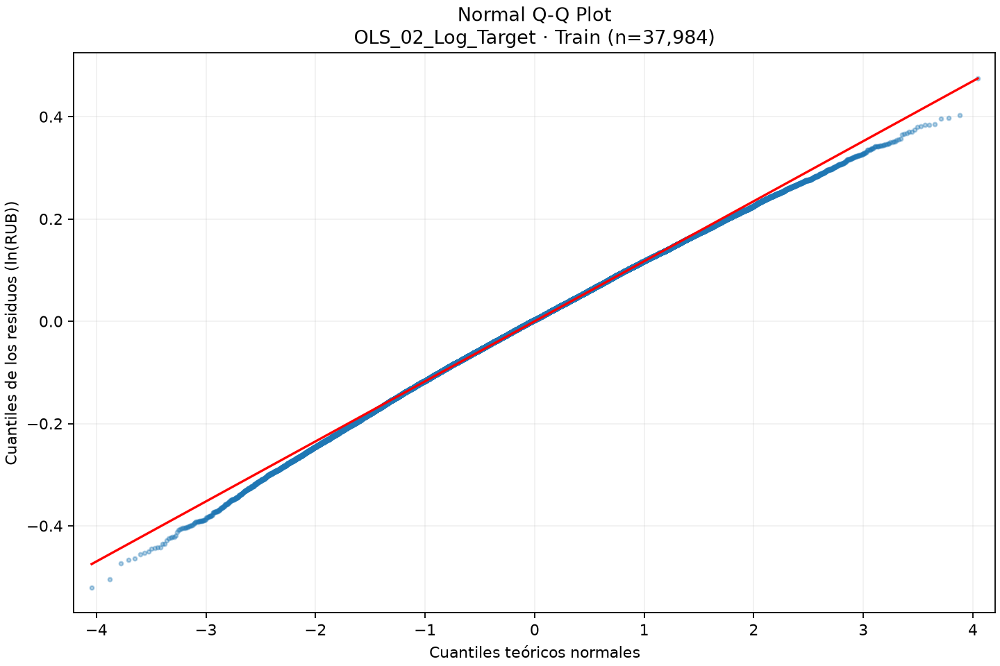
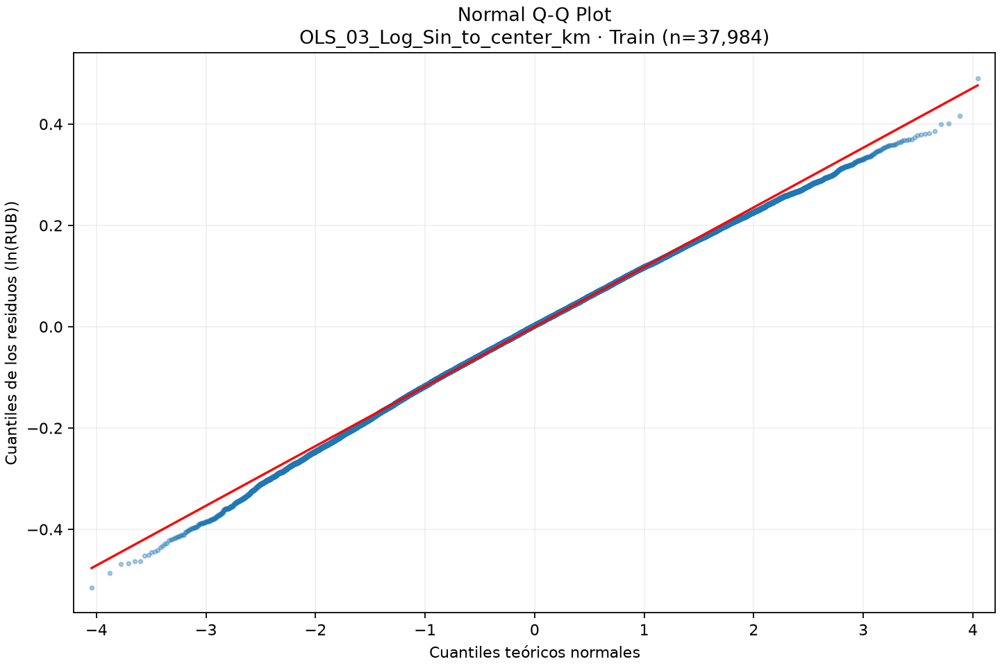
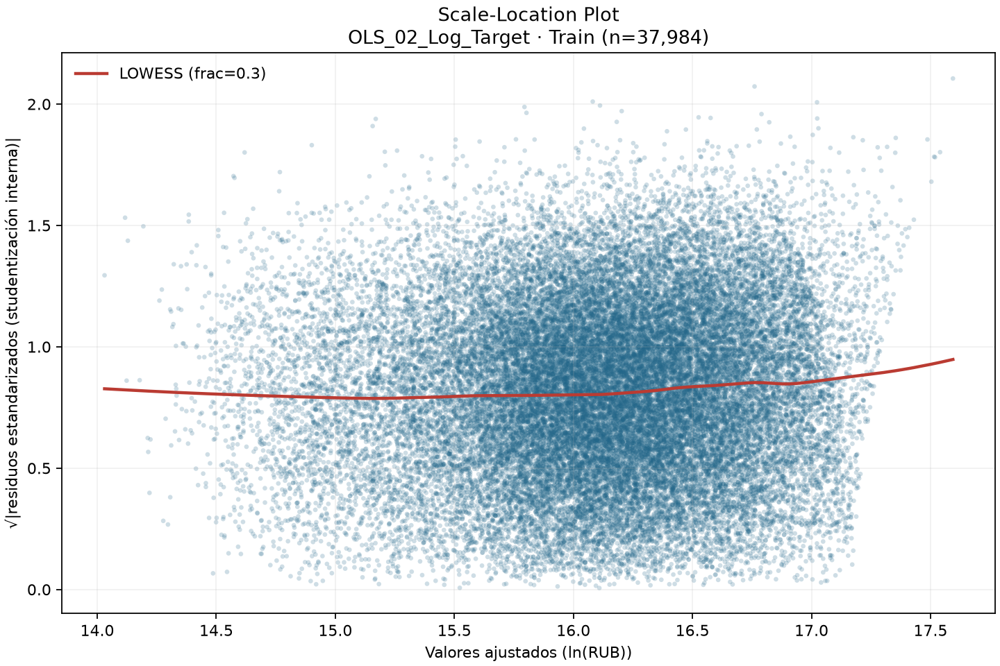
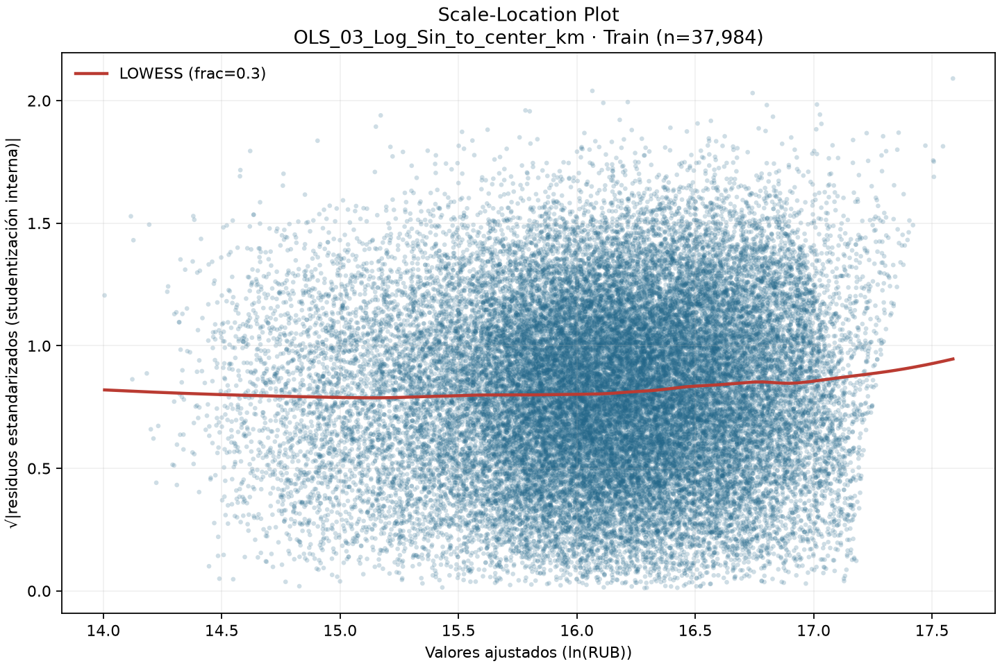
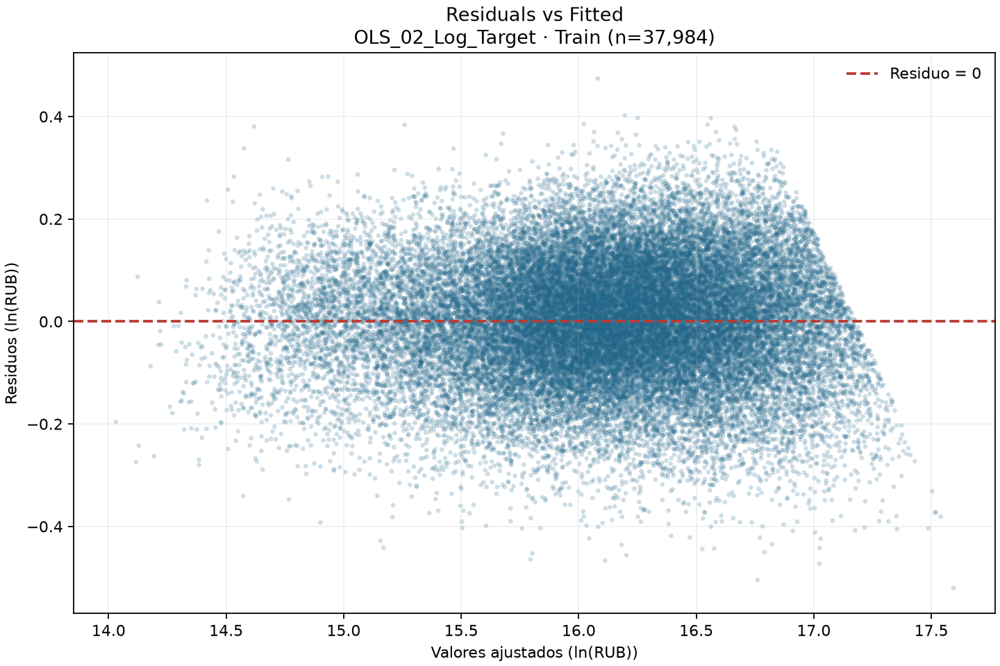
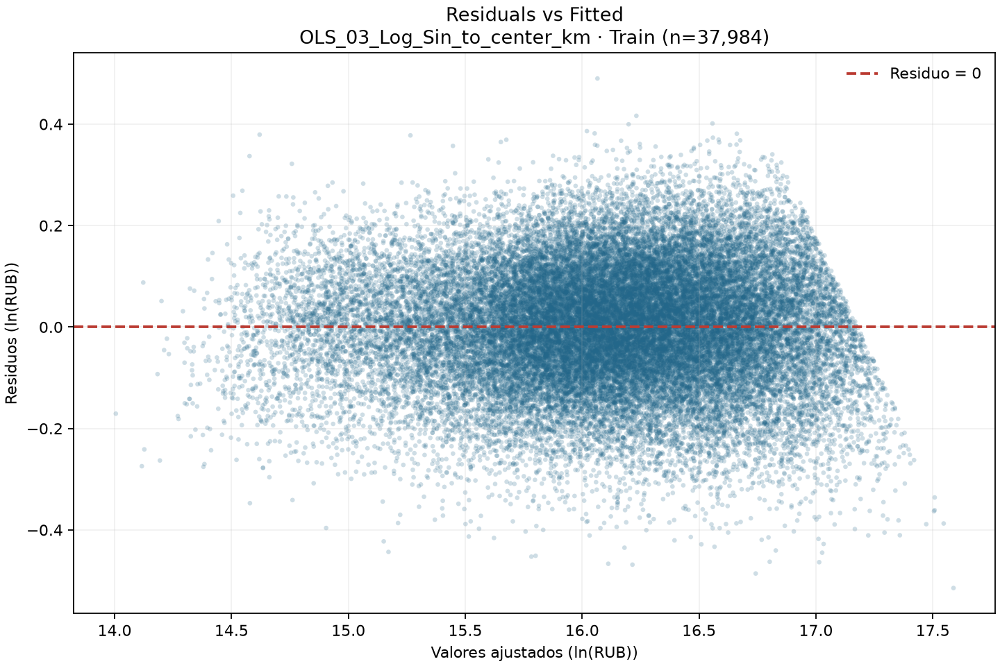

In [20]:
with sesion.paso():
    rutas_graficos_referencia_03 = {nombre: archivos_referencia_03["diagnosticos_residuales/" + nombre] for nombre in dr.ARCHIVOS}
    display(HTML(dr.comparar_diagnosticos_residuales(
        rutas_graficos_referencia_03, salida_03 / "diagnosticos_residuales",
        nombre_referencia="OLS_02_Log_Target", nombre_nuevo=NOMBRE_03,
        unidad_referencia="ln(RUB)", unidad_nuevo="ln(RUB)",
        archivo_html=salida_03 / "comparacion_residuos.html")))


## 16. Interpretación de la exclusión de to_center_km

Las conclusiones se limitan a la comparación con OLS_02_Log_Target en las mismas filas de Train. No se define una tolerancia de equivalencia práctica a posteriori ni se elige un modelo definitivo.


In [21]:
with sesion.paso():
    variacion_mae_03 = 100 * (metricas_03["train_mae_original"] / metricas_referencia_03["train_mae_original"] - 1)
    variacion_rmse_03 = 100 * (metricas_03["train_rmse_original"] / metricas_referencia_03["train_rmse_original"] - 1)
    reduccion_vif_03 = 100 * (1 - metricas_03["train_vif_max"] / metricas_referencia_03["train_vif_max"])
    interpretacion_03 = f"""# OLS_03_Log_Sin_to_center_km frente a OLS_02_Log_Target

    La exclusión reduce el VIF máximo de {metricas_referencia_03['train_vif_max']:.4f} a {metricas_03['train_vif_max']:.4f} (−{reduccion_vif_03:.2f} %), y el VIF promedio de {metricas_referencia_03['train_vif_mean']:.4f} a {metricas_03['train_vif_mean']:.4f}. Los conteos VIF > 5 pasan de {metricas_referencia_03['train_vif_gt5_count']:.0f} a {metricas_03['train_vif_gt5_count']:.0f}, y VIF > 10 de {metricas_referencia_03['train_vif_gt10_count']:.0f} a {metricas_03['train_vif_gt10_count']:.0f}. El Condition Number baja de {metricas_referencia_03['train_condition_number']:.2f} a {metricas_03['train_condition_number']:.2f}; el condicionamiento mejora, pero no desaparecen todos los indicios de multicolinealidad.

    El R² ajustado log cambia de {metricas_referencia_03['train_r2_adj_log']:.9f} a {metricas_03['train_r2_adj_log']:.9f}, Δ={metricas_03['train_r2_adj_log']-metricas_referencia_03['train_r2_adj_log']:.9f}. AIC empeora {metricas_03['train_aic_log']-metricas_referencia_03['train_aic_log']:.2f} y BIC {metricas_03['train_bic_log']-metricas_referencia_03['train_bic_log']:.2f} unidades: ambos favorecen al modelo completo, pese al parámetro adicional. El aporte incremental de to_center_km al R² log es {metricas_03['incremental_r2_removed_predictor_log']:.9f} ({100*metricas_03['incremental_r2_removed_predictor_log']:.5f} puntos porcentuales); su R² parcial es {metricas_03['partial_r2_removed_predictor_log']:.6f}.

    En precios originales, manteniendo exp sin corrección, MAE aumenta {metricas_03['train_mae_original']-metricas_referencia_03['train_mae_original']:.2f} RUB (+{variacion_mae_03:.3f} %) y RMSE {metricas_03['train_rmse_original']-metricas_referencia_03['train_rmse_original']:.2f} RUB (+{variacion_rmse_03:.3f} %). En ln(RUB), MAE aumenta {metricas_03['train_mae_log']-metricas_referencia_03['train_mae_log']:.8f} y RMSE {metricas_03['train_rmse_log']-metricas_referencia_03['train_rmse_log']:.8f}. Son cambios pequeños en Train, no una demostración de equivalencia ni de rendimiento fuera de muestra.

    El coeficiente recuperado de to_center_km es {metricas_03['removed_predictor_coefficient_log']:.9f}, referido a la unidad de la predictora ya transformada; t nominal={metricas_03['removed_predictor_t_nonrobust']:.4f} y p nominal={metricas_03['removed_predictor_pvalue_nonrobust']:.3e}. El F parcial algebraico es {metricas_03['partial_f_descriptive']:.4f}, solo descriptivo: no se informa un p-value clásico válido porque hay heterocedasticidad. Como sensibilidad, Wald HC3={metricas_03['removed_predictor_wald_hc3']:.4f}, p={metricas_03['removed_predictor_pvalue_hc3']:.3e}. Bajo independencia de observaciones, HC3 respalda una contribución distinta de cero; no resuelve posible dependencia temporal o por grupos. Un VIF alto no convierte a esta variable en estadísticamente irrelevante.

    Entre los coeficientes restantes cambian de significancia nominal {metricas_03['n_significance_changes']:.0f}: {metricas_03['n_nonsignificant_to_significant']:.0f} pasan a p ≤ 0,05 y {metricas_03['n_significant_to_nonsignificant']:.0f} deja de cumplir ese umbral. El total no significativo pasa de {metricas_referencia_03['train_n_coefficients_p_gt_005_log']:.0f} a {metricas_03['train_n_coefficients_p_gt_005_log']:.0f}; incluye el intercepto. Estos cambios nonrobust se documentan en el CSV, no son evidencia suficiente para nuevas exclusiones.

    Los QQ-Plot, Scale-Location y Residuos vs ajustados son visualmente muy parecidos entre ambos modelos, con desviaciones en las colas y estructura en los mayores ajustados. Breusch-Pagan sigue rechazando homocedasticidad (p={metricas_03['train_bp_lm_pvalue_log']:.3e}) y Jarque-Bera normalidad (p={metricas_03['train_jarque_bera_pvalue_log']:.3e}). Quitar la variable no resuelve estos supuestos.

    La reducción de multicolinealidad es grande y el deterioro empírico del error de Train es menor al 0,4 %. Eso presenta un intercambio atendible si se prioriza menor colinealidad, pero no una mejora en todos los criterios: la variable tiene aporte estadístico y AIC/BIC prefieren conservarla. Sin un umbral de equivalencia predefinido ni evaluación fuera de muestra, no se afirma que la reducción compense definitivamente la pérdida ni se determina el modelo final. No se utilizó Test ni se eliminó ninguna otra variable u observación.
    """
    (salida_03 / "interpretacion.md").write_text(interpretacion_03, encoding="utf-8")
    display(Markdown(interpretacion_03))


# OLS_03_Log_Sin_to_center_km frente a OLS_02_Log_Target

La exclusión reduce el VIF máximo de 102.5843 a 17.4312 (−83.01 %), y el VIF promedio de 3.6683 a 2.2438. Los conteos VIF > 5 pasan de 18 a 4, y VIF > 10 de 11 a 3. El Condition Number baja de 19159.17 a 14533.72; el condicionamiento mejora, pero no desaparecen todos los indicios de multicolinealidad.

El R² ajustado log cambia de 0.955486757 a 0.955180600, Δ=-0.000306157. AIC empeora 259.36 y BIC 250.81 unidades: ambos favorecen al modelo completo, pese al parámetro adicional. El aporte incremental de to_center_km al R² log es 0.000305910 (0.03059 puntos porcentuales); su R² parcial es 0.006857.

En precios originales, manteniendo exp sin corrección, MAE aumenta 3840.31 RUB (+0.351 %) y RMSE 5091.14 RUB (+0.323 %). En ln(RUB), MAE aumenta 0.00033265 y RMSE 0.00040462. Son cambios pequeños en Train, no una demostración de equivalencia ni de rendimiento fuera de muestra.

El coeficiente recuperado de to_center_km es -0.007749871, referido a la unidad de la predictora ya transformada; t nominal=-16.1565 y p nominal=1.606e-58. El F parcial algebraico es 261.0319, solo descriptivo: no se informa un p-value clásico válido porque hay heterocedasticidad. Como sensibilidad, Wald HC3=260.3070, p=1.471e-58. Bajo independencia de observaciones, HC3 respalda una contribución distinta de cero; no resuelve posible dependencia temporal o por grupos. Un VIF alto no convierte a esta variable en estadísticamente irrelevante.

Entre los coeficientes restantes cambian de significancia nominal 6: 5 pasan a p ≤ 0,05 y 1 deja de cumplir ese umbral. El total no significativo pasa de 26 a 22; incluye el intercepto. Estos cambios nonrobust se documentan en el CSV, no son evidencia suficiente para nuevas exclusiones.

Los QQ-Plot, Scale-Location y Residuos vs ajustados son visualmente muy parecidos entre ambos modelos, con desviaciones en las colas y estructura en los mayores ajustados. Breusch-Pagan sigue rechazando homocedasticidad (p=3.541e-148) y Jarque-Bera normalidad (p=1.235e-39). Quitar la variable no resuelve estos supuestos.

La reducción de multicolinealidad es grande y el deterioro empírico del error de Train es menor al 0,4 %. Eso presenta un intercambio atendible si se prioriza menor colinealidad, pero no una mejora en todos los criterios: la variable tiene aporte estadístico y AIC/BIC prefieren conservarla. Sin un umbral de equivalencia predefinido ni evaluación fuera de muestra, no se afirma que la reducción compense definitivamente la pérdida ni se determina el modelo final. No se utilizó Test ni se eliminó ninguna otra variable u observación.


## 17. Registro y verificación del tercer Run

Se registra únicamente OLS_03_Log_Sin_to_center_km en el experimento activo existente. Se conservan las métricas, los diagnósticos de importancia, la tabla comparativa, los cambios de significancia, el resumen y el modelo reproducible. Los tres PNG se registran bajo `diagnosticos_residuales`. Se descargan los artefactos y se comparan sus hashes; también se comprueba que el Run de referencia no haya cambiado.


In [22]:
with sesion.paso():
    registro_03 = b.registrar(cliente, salida_03, contexto_03, metricas_03, nombre_run=NOMBRE_03)
    remoto_03 = cliente.get_run(registro_03["run_id"])
    assert remoto_03.info.status == "FINISHED" and remoto_03.info.experiment_id == referencia_03.info.experiment_id
    assert remoto_03.data.params["excluded_predictors"] == "to_center_km"
    assert remoto_03.data.params["reference_run_id"] == referencia_03.info.run_id
    assert remoto_03.data.params["n_predictors"] == "176" and remoto_03.data.params["n_train"] == "37984"
    assert remoto_03.data.params["target_transform"] == "ln(Target)" and remoto_03.data.params["bias_correction"] == "none"
    assert "partial_f_pvalue" not in remoto_03.data.metrics
    for clave, valor in metricas_03.items():
        assert remoto_03.data.metrics[clave] == valor
    referencia_despues_03 = cliente.get_run(referencia_03.info.run_id)
    assert referencia_despues_03.info.status == referencia_03.info.status
    assert referencia_despues_03.data.metrics == referencia_03.data.metrics
    assert referencia_despues_03.data.params == referencia_03.data.params
    assert b.sha256(base / contexto_03["csv"]) == contexto_03["dataset_sha256"]
    print("Run:", registro_03["run_id"], "— FINISHED")
    print("Verificados:", len(metricas_03), "métricas exactas; parámetros; modelo; tablas y tres PNG descargados.")
    print("Mismas filas; única exclusión: to_center_km; referencia intacta; Test no utilizado. Fin del Experimento 03.")
    display(Markdown(f"[Abrir {NOMBRE_03} en DagsHub]({registro_03['url']})"))


🏃 View run OLS_03_Log_Sin_to_center_km at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/7dfbe14054724f099428fcda7fbe92b7
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5
Run: 7dfbe14054724f099428fcda7fbe92b7 — FINISHED
Verificados: 61 métricas exactas; parámetros; modelo; tablas y tres PNG descargados.
Mismas filas; única exclusión: to_center_km; referencia intacta; Test no utilizado. Fin del Experimento 03.


[Abrir OLS_03_Log_Sin_to_center_km en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/7dfbe14054724f099428fcda7fbe92b7)

Fin del Experimento 03. Su flujo se centraliza en preparar_ablacion/evaluar_ablacion para reutilizarlo en la siguiente exclusión; no se reentrena ni se modifica su Run durante el Experimento 04.


# Experimento 04 — OLS logarítmico sin living_area

Referencia exclusiva: **OLS_03_Log_Sin_to_center_km**. Nuevo Run: **OLS_04_Log_Sin_living_area**. Se reutiliza el DataFrame X_03, manteniendo las 37.984 observaciones y la exclusión de to_center_km. El único cambio es quitar living_area: quedan 175 predictoras más el intercepto. Se conserva ln(price_rub), OLS nonrobust/pinv y exp sin corrección para predecir precios.

El flujo compartido recupera el modelo y las métricas del Run anterior sin reentrenarlo, calcula los diagnósticos y exporta los artefactos. Las diferencias corresponden únicamente a las métricas train_* de los dos ajustes; los indicadores de aporte del Run 03 se referían a otra variable y no se comparan como si midieran living_area.


In [23]:
with sesion.paso():
    NOMBRE_04 = "OLS_04_Log_Sin_living_area"
    datos_04 = b.preparar_ablacion(cliente, base, X_03, y_ln_log, y_precio_log,
        registro_referencia=registro_03, variable="living_area", nombre_run=NOMBRE_04,
        carpeta_salida=sesion.carpeta("ols_04_log_sin_living_area"))
    assert datos_04["X"].shape == (37984, 175)
    assert datos_04["contexto"]["predictoras_excluidas"] == ["to_center_km", "living_area"]
    assert "total_area" in datos_04["X"] and "to_center_km" not in datos_04["X"]
    modelo_04, diseno_04 = b.ajustar(datos_04["X"], y_ln_log)
    assert int(modelo_04.nobs) == 37984 and modelo_04.model.rank == 176
    b.pd.testing.assert_series_equal(y_precio_log, y_precio_intacto_log)
    print("Ajuste verificado: mismas 37.984 filas; 175 predictoras; intercepto; única nueva exclusión: living_area.")


Ajuste verificado: mismas 37.984 filas; 175 predictoras; intercepto; única nueva exclusión: living_area.


## 18. Métricas y aporte incremental de living_area

Se reutiliza la evaluación de ablaciones para registrar las mismas métricas logarítmicas y en RUB, los resúmenes de VIF, el aporte incremental, los cambios de coeficientes y de significancia nominal. El F parcial es solo descriptivo porque el modelo anterior presenta heterocedasticidad; se omite su p-value clásico. El Wald HC3 complementario supone independencia de filas y no cambia el modelo.

La relación con total_area se documenta mediante su correlación de Pearson en las columnas transformadas de Train y los cambios de VIF y coeficientes condicionales. Una correlación alta, por sí sola, no demuestra redundancia. Las tablas completas de coeficientes y significancia quedan en los CSV; aquí se muestra la comparación necesaria. **Δ = Experimento 04 − Experimento 03.**


In [24]:
with sesion.paso():
    resultado_04 = b.evaluar_ablacion(datos_04, modelo_04, diseno_04, relacionadas=("total_area",))
    display(Markdown(resultado_04["comparacion_md"]))
    display(resultado_04["relacion"])
    cambios_04 = resultado_04["cambios"]
    if cambios_04["cambia"].any():
        display(cambios_04.loc[cambios_04["cambia"]].head(12))


# OLS_04_Log_Sin_living_area frente a OLS_03_Log_Sin_to_center_km — Train

Referencia MLflow: 7dfbe14054724f099428fcda7fbe92b7. Mismas filas, ln(RUB), exp sin corrección. Δ = nuevo − referencia.

| Métrica | OLS_03_Log_Sin_to_center_km | OLS_04_Log_Sin_living_area | Diferencia |
|---|---|---|---|
| R² (ln(RUB)) | 0.955388277995 | 0.955387057668 | -1.22032695749e-06 |
| R² ajustado (ln(RUB)) | 0.955180600499 | 0.955180559971 | -4.05279128035e-08 |
| MAE (ln(RUB)) | 0.0936698768163 | 0.0936729403337 | 3.06351732762e-06 |
| RMSE (ln(RUB)) | 0.11781076368 | 0.117812374991 | 1.61131044908e-06 |
| RSS (ln(RUB)) | 527.194219464 | 527.208640547 | 0.0144210823722 |
| MSE (ln(RUB)) | 0.013879376039 | 0.013879755701 | 3.79662025384e-07 |
| AIC (ln(RUB)) | -54322.9884864 | -54323.949471 | -0.960984622448 |
| BIC (ln(RUB)) | -52810.5375938 | -52820.0434987 | -9.50590491986 |
| F-statistic (ln(RUB)) | 4600.34572177 | 4626.62331834 | 26.2775965726 |
| Probabilidad F-statistic (ln(RUB)) | 0 | 0 | 0 |
| n_obs | 37984 | 37984 | 0 |
| n_predictors | 176 | 175 | -1 |
| n_parameters_effective | 177 | 176 | -1 |
| n_coefficients | 177 | 176 | -1 |
| df_model | 176 | 175 | -1 |
| df_resid | 37807 | 37808 | 1 |
| log_likelihood (ln(RUB)) | 27338.4942432 | 27337.9747355 | -0.519507688776 |
| Durbin-Watson (ln(RUB)) | 1.79682392767 | 1.79666881869 | -0.000155108985642 |
| n_coefficients_p_gt_005 (ln(RUB)) | 22 | 21 | -1 |
| n_coefficients_p_undefined (ln(RUB)) | 0 | 0 | 0 |
| condition_number | 14533.7195965 | 13585.6160774 | -948.103519156 |
| rank_deficiency | 0 | 0 | 0 |
| jarque_bera (ln(RUB)) | 179.17967428 | 178.832331322 | -0.347342957973 |
| jarque_bera_pvalue (ln(RUB)) | 1.23488949282e-39 | 1.46910440315e-39 | 2.34214910331e-40 |
| skewness (ln(RUB)) | -0.163908965601 | -0.163748101704 | 0.000160863896994 |
| kurtosis (ln(RUB)) | 3.0758233672 | 3.07576640995 | -5.69572444484e-05 |
| omnibus (ln(RUB)) | 176.476612361 | 176.139158049 | -0.337454312014 |
| omnibus_pvalue (ln(RUB)) | 4.7707925594e-39 | 5.64765041049e-39 | 8.7685785109e-40 |
| VIF máximo | 17.4312021082 | 10.6358240947 | -6.79537801352 |
| VIF promedio | 2.24384256672 | 2.10446526252 | -0.139377304197 |
| Cantidad VIF > 5 | 4 | 2 | -2 |
| Cantidad VIF > 10 | 3 | 1 | -2 |
| vif_infinite_count | 0 | 0 | 0 |
| vif_undefined_count | 0 | 0 | 0 |
| bp_lm (ln(RUB)) | 1180.14332552 | 1178.31105751 | -1.83226801458 |
| bp_lm_pvalue (ln(RUB)) | 3.54121812942e-148 | 2.97351914358e-148 | -5.67698985845e-149 |
| bp_f (ln(RUB)) | 6.88812426253 | 6.91656810087 | 0.0284438383458 |
| bp_f_pvalue (ln(RUB)) | 4.03799297691e-151 | 3.42998495637e-151 | -6.08008020543e-152 |
| R² (precio original) | 0.927055578331 | 0.927055846322 | 2.67990846847e-07 |
| R² ajustado (precio original) | 0.926716005812 | 0.926718213363 | 2.20755106128e-06 |
| MAE (precio original) | 1097249.03335 | 1097287.47669 | 38.4433370959 |
| RMSE (precio original) | 1580889.49377 | 1580886.58975 | -2.90402126522 |
| MAPE (precio original) | 9.44103877685 | 9.44133613346 | 0.000297356609341 |
| RSS (precio original) | 9.49300530921e+16 | 9.49297043281e+16 | -348763959488 |
| MSE (precio original) | 2.49921159151e+12 | 2.49920240965e+12 | -9181864.98242 |

## Aporte de living_area

| Diagnóstico | Valor |
|---|---|
| incremental_r2_removed_predictor_log | 1.22032695741e-06 |
| partial_r2_removed_predictor_log | 2.73536533037e-05 |
| partial_f_descriptive | 1.03418785927 |
| partial_f_df_num | 1 |
| partial_f_df_den | 37807 |
| partial_f_classical_inference_valid | 0 |
| removed_predictor_coefficient_log | 0.000209097738886 |
| removed_predictor_t_nonrobust | 1.01695027374 |
| removed_predictor_pvalue_nonrobust | 0.309183593206 |
| removed_predictor_se_hc3 | 0.000208760123331 |
| removed_predictor_wald_hc3 | 1.00323709866 |
| removed_predictor_pvalue_hc3 | 0.316528490488 |
| n_significance_changes | 0 |
| n_significant_to_nonsignificant | 0 |
| n_nonsignificant_to_significant | 0 |
| removed_predictor_vif_reference | 13.8574008587 |
| related_total_area_correlation_train | 0.963059708981 |
| related_total_area_vif_reference | 17.4312021082 |
| related_total_area_vif_new | 4.66299349574 |
| related_total_area_coefficient_reference_log | 0.0156505766983 |
| related_total_area_coefficient_new_log | 0.0157807225727 |
| related_total_area_pvalue_reference_nonrobust | 0 |
| related_total_area_pvalue_new_nonrobust | 0 |

F parcial solo descriptivo: p-value clásico omitido por supuestos no verificados; HC3 supone independencia de filas. Cambios de significancia nominales (nonrobust). Correlaciones, cuando se incluyen, corresponden a las columnas transformadas de Train.


,eliminada,predictora_relacionada,correlation_train,vif_reference,vif_new,coefficient_reference_log,coefficient_new_log,pvalue_reference_nonrobust,pvalue_new_nonrobust
0,living_area,total_area,0.96306,17.431202,4.662993,0.015651,0.015781,0.0,0.0


## 19. Diagnósticos gráficos de ambos modelos

Izquierda: OLS_03 descargado de MLflow. Derecha: OLS_04. QQ-Plot, Scale-Location y Residuos vs ajustados utilizan las mismas observaciones, residuos ln(RUB), estandarización y suavizado de los experimentos anteriores. Los PNG del nuevo modelo se guardan en diagnosticos_residuales.


OLS_03_Log_Sin_to_center_km · ln(RUB),OLS_04_Log_Sin_living_area · ln(RUB)
,
,
,

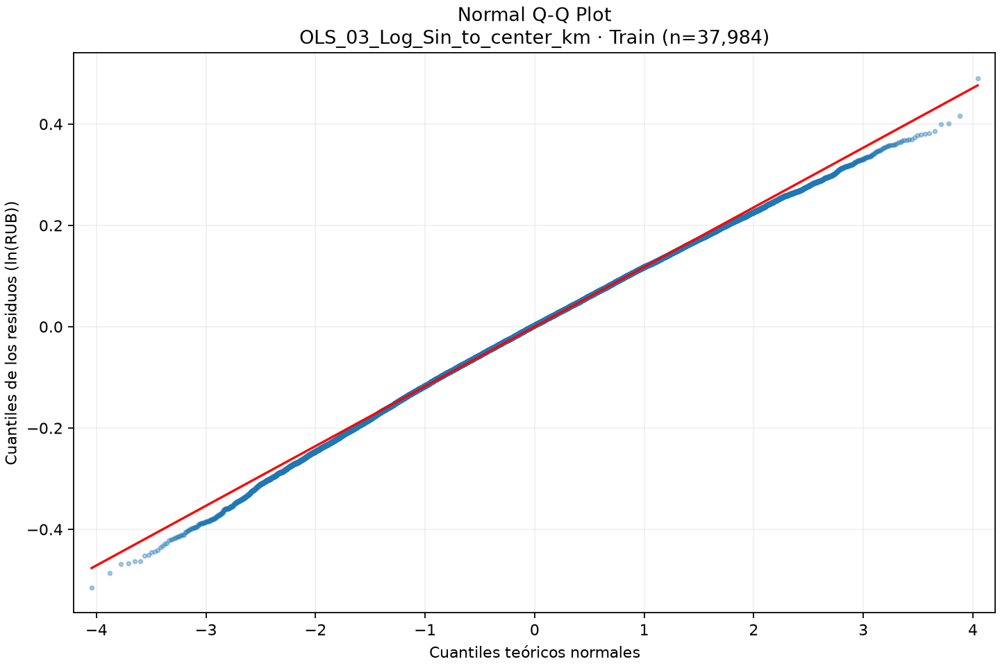
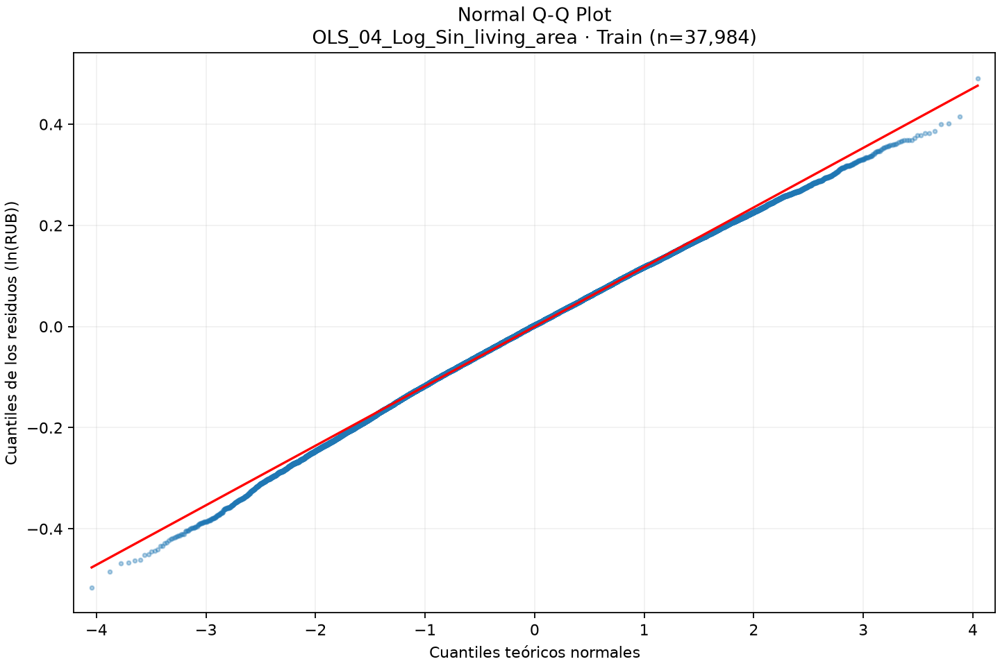
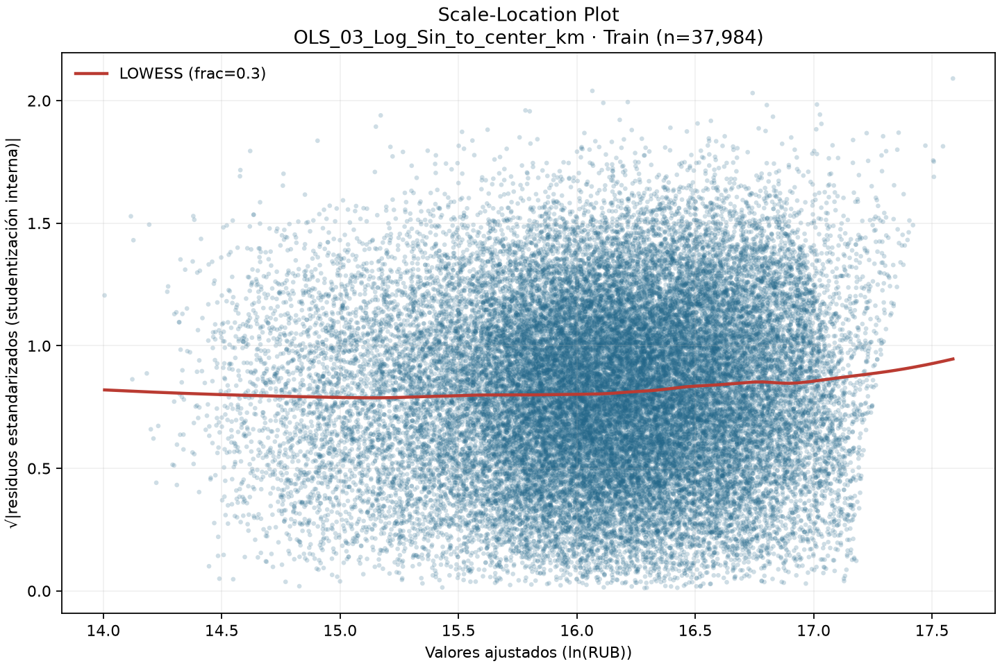
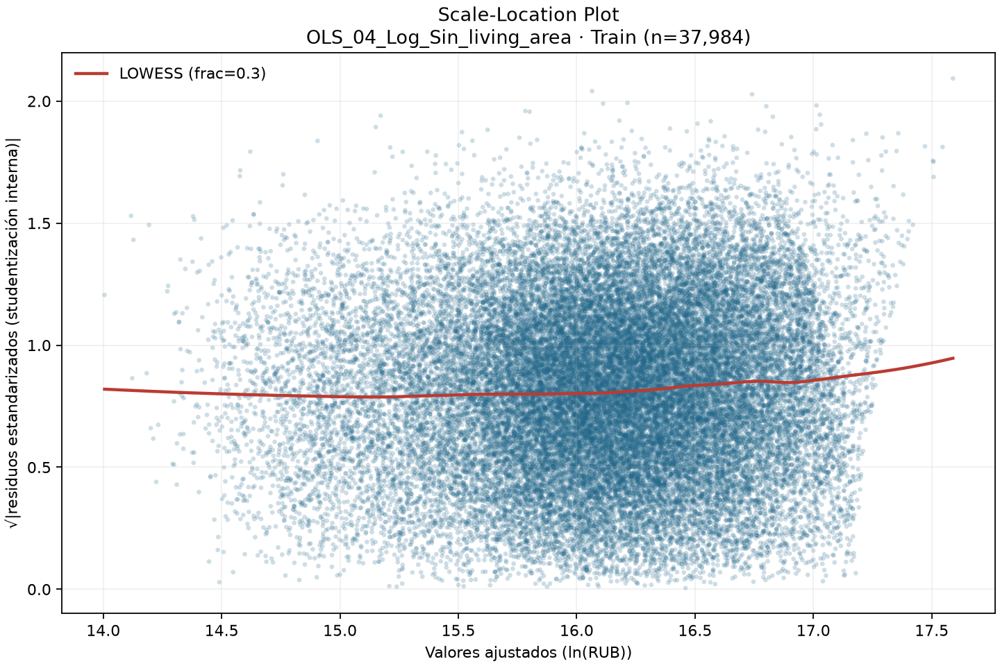
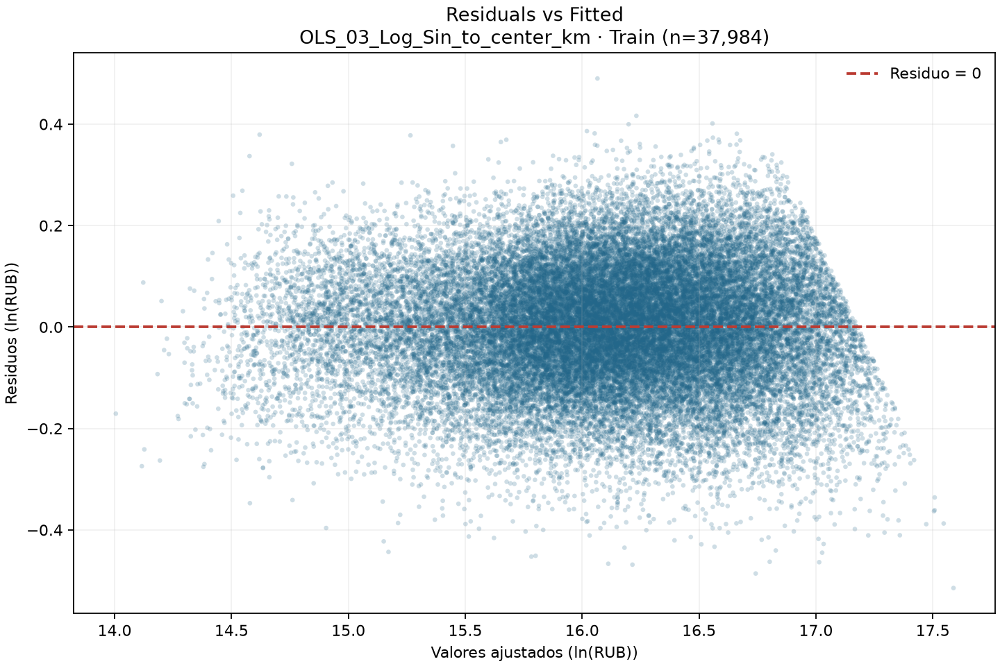
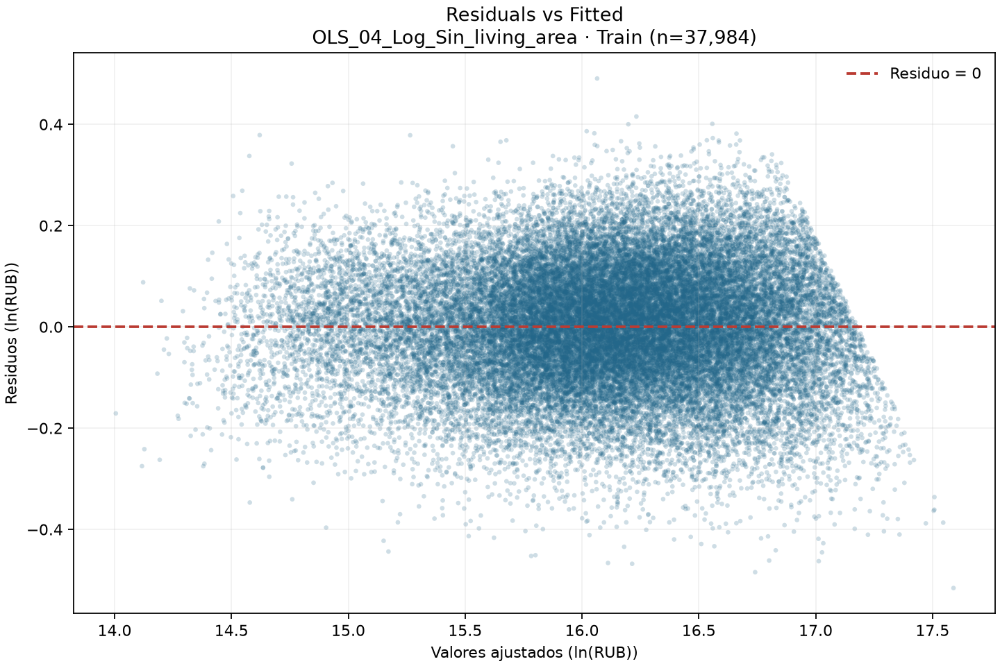

In [25]:
with sesion.paso():
    display(HTML(dr.comparar_diagnosticos_residuales(
        {nombre: datos_04["archivos"]["diagnosticos_residuales/" + nombre] for nombre in dr.ARCHIVOS},
        datos_04["salida"] / "diagnosticos_residuales",
        nombre_referencia="OLS_03_Log_Sin_to_center_km", nombre_nuevo=NOMBRE_04,
        unidad_referencia="ln(RUB)", unidad_nuevo="ln(RUB)",
        archivo_html=datos_04["salida"] / "comparacion_residuos.html")))


## 20. Interpretación acotada al Experimento 04

La comparación se limita al modelo anterior y las mismas filas de Train. No se considera que una correlación alta o un p-value no significativo demuestren, por sí solos, redundancia exacta o equivalencia predictiva fuera de muestra.


In [26]:
with sesion.paso():
    m04, r04 = resultado_04["metricas"], datos_04["metricas_referencia"]
    interpretacion_04 = f"""# OLS_04_Log_Sin_living_area frente a OLS_03_Log_Sin_to_center_km

    living_area y total_area presentan correlación de Pearson {m04['related_total_area_correlation_train']:.4f} en las columnas transformadas de Train. Al excluir living_area, el VIF de total_area baja de {m04['related_total_area_vif_reference']:.4f} a {m04['related_total_area_vif_new']:.4f}; el VIF máximo pasa de {r04['train_vif_max']:.4f} a {m04['train_vif_max']:.4f} y el promedio de {r04['train_vif_mean']:.4f} a {m04['train_vif_mean']:.4f}. Los conteos VIF > 5 / > 10 pasan de {r04['train_vif_gt5_count']:.0f} / {r04['train_vif_gt10_count']:.0f} a {m04['train_vif_gt5_count']:.0f} / {m04['train_vif_gt10_count']:.0f}. El Condition Number disminuye de {r04['train_condition_number']:.2f} a {m04['train_condition_number']:.2f}; la colinealidad se reduce, aunque no desaparece completamente.

    El aporte incremental de living_area al R² log del modelo anterior es {m04['incremental_r2_removed_predictor_log']:.9g}; el R² ajustado cambia {m04['train_r2_adj_log']-r04['train_r2_adj_log']:.3e}. AIC baja {r04['train_aic_log']-m04['train_aic_log']:.3f} y BIC {r04['train_bic_log']-m04['train_bic_log']:.3f}: ambos favorecen al modelo reducido, con una diferencia pequeña en AIC. En precios originales, MAE aumenta {m04['train_mae_original']-r04['train_mae_original']:.2f} RUB ({100*(m04['train_mae_original']/r04['train_mae_original']-1):+.5f} %) y RMSE cambia {m04['train_rmse_original']-r04['train_rmse_original']:.2f} RUB ({100*(m04['train_rmse_original']/r04['train_rmse_original']-1):+.5f} %). Son variaciones empíricas mínimas en Train, no una prueba de equivalencia.

    El coeficiente recuperado de living_area es {m04['removed_predictor_coefficient_log']:.9f}, t nominal={m04['removed_predictor_t_nonrobust']:.4f}, p nominal={m04['removed_predictor_pvalue_nonrobust']:.4f}. Wald HC3={m04['removed_predictor_wald_hc3']:.4f}, p={m04['removed_predictor_pvalue_hc3']:.4f}: bajo independencia de filas, no se detecta aporte adicional al 5 %; no se demuestra un efecto exactamente nulo. El F parcial ({m04['partial_f_descriptive']:.4f}) es solo descriptivo; se omite el p-value clásico por heterocedasticidad. HC3 no corrige dependencia temporal o por grupos.

    No cambia la significancia nominal de los coeficientes restantes ({m04['n_significance_changes']:.0f} cambios). El total no significativo pasa de {r04['train_n_coefficients_p_gt_005_log']:.0f} a {m04['train_n_coefficients_p_gt_005_log']:.0f} únicamente porque se retiró living_area. El coeficiente condicional de total_area cambia de {m04['related_total_area_coefficient_reference_log']:.9f} a {m04['related_total_area_coefficient_new_log']:.9f}; los demás cambios están documentados en cambios_significancia.csv, sin nuevas exclusiones.

    Los tres gráficos de residuos son prácticamente iguales a los del Experimento 03. Persisten desviaciones en las colas y heterocedasticidad (Breusch-Pagan p={m04['train_bp_lm_pvalue_log']:.3e}). En este diseño, los resultados son compatibles con que gran parte de la información de living_area esté compartida con otras superficies, especialmente total_area: quitarla mejora la colinealidad sin un deterioro apreciable observado en Train. No se afirma redundancia universal ni superioridad fuera de muestra. Se mantienen to_center_km excluida, las mismas 37.984 filas y ln(price_rub); no se utilizó Test ni se entrenaron otros modelos.
    """
    (datos_04["salida"] / "interpretacion.md").write_text(interpretacion_04, encoding="utf-8")
    display(Markdown(interpretacion_04))


# OLS_04_Log_Sin_living_area frente a OLS_03_Log_Sin_to_center_km

living_area y total_area presentan correlación de Pearson 0.9631 en las columnas transformadas de Train. Al excluir living_area, el VIF de total_area baja de 17.4312 a 4.6630; el VIF máximo pasa de 17.4312 a 10.6358 y el promedio de 2.2438 a 2.1045. Los conteos VIF > 5 / > 10 pasan de 4 / 3 a 2 / 1. El Condition Number disminuye de 14533.72 a 13585.62; la colinealidad se reduce, aunque no desaparece completamente.

El aporte incremental de living_area al R² log del modelo anterior es 1.22032696e-06; el R² ajustado cambia -4.053e-08. AIC baja 0.961 y BIC 9.506: ambos favorecen al modelo reducido, con una diferencia pequeña en AIC. En precios originales, MAE aumenta 38.44 RUB (+0.00350 %) y RMSE cambia -2.90 RUB (-0.00018 %). Son variaciones empíricas mínimas en Train, no una prueba de equivalencia.

El coeficiente recuperado de living_area es 0.000209098, t nominal=1.0170, p nominal=0.3092. Wald HC3=1.0032, p=0.3165: bajo independencia de filas, no se detecta aporte adicional al 5 %; no se demuestra un efecto exactamente nulo. El F parcial (1.0342) es solo descriptivo; se omite el p-value clásico por heterocedasticidad. HC3 no corrige dependencia temporal o por grupos.

No cambia la significancia nominal de los coeficientes restantes (0 cambios). El total no significativo pasa de 22 a 21 únicamente porque se retiró living_area. El coeficiente condicional de total_area cambia de 0.015650577 a 0.015780723; los demás cambios están documentados en cambios_significancia.csv, sin nuevas exclusiones.

Los tres gráficos de residuos son prácticamente iguales a los del Experimento 03. Persisten desviaciones en las colas y heterocedasticidad (Breusch-Pagan p=2.974e-148). En este diseño, los resultados son compatibles con que gran parte de la información de living_area esté compartida con otras superficies, especialmente total_area: quitarla mejora la colinealidad sin un deterioro apreciable observado en Train. No se afirma redundancia universal ni superioridad fuera de muestra. Se mantienen to_center_km excluida, las mismas 37.984 filas y ln(price_rub); no se utilizó Test ni se entrenaron otros modelos.


## 21. Registro y verificación de OLS_04_Log_Sin_living_area

Se agrega solo un nuevo Run al experimento existente. Se registran todas las métricas, modelo, resumen OLS, tablas, cambios de coeficientes y significancia, relación de superficies y gráficos. La verificación descarga y compara los artefactos, comprueba el estado FINISHED y la igualdad exacta de las métricas numéricas. El Run 03 permanece intacto.


In [27]:
with sesion.paso():
    registro_04 = b.registrar(cliente, datos_04["salida"], datos_04["contexto"],
        resultado_04["metricas"], nombre_run=NOMBRE_04)
    remoto_04 = cliente.get_run(registro_04["run_id"])
    ref_despues_04 = cliente.get_run(datos_04["referencia"].info.run_id)
    assert remoto_04.info.status == "FINISHED" and remoto_04.info.experiment_id == datos_04["referencia"].info.experiment_id
    assert remoto_04.data.params["excluded_predictors"] == "to_center_km,living_area"
    assert remoto_04.data.params["reference_run_id"] == datos_04["referencia"].info.run_id
    assert remoto_04.data.params["n_predictors"] == "175" and remoto_04.data.params["n_train"] == "37984"
    assert remoto_04.data.params["target_transform"] == "ln(Target)" and remoto_04.data.params["bias_correction"] == "none"
    assert "partial_f_pvalue" not in remoto_04.data.metrics
    assert all(remoto_04.data.metrics[k] == v for k,v in resultado_04["metricas"].items())
    assert ref_despues_04.info.status == datos_04["referencia"].info.status
    assert ref_despues_04.data.metrics == datos_04["referencia"].data.metrics
    assert ref_despues_04.data.params == datos_04["referencia"].data.params
    assert b.sha256(base / datos_04["contexto"]["csv"]) == datos_04["contexto"]["dataset_sha256"]
    print("Run:", registro_04["run_id"], "— FINISHED")
    print("Verificados:", len(resultado_04["metricas"]), "métricas exactas; modelo, tablas y tres PNG descargados.")
    print("175 predictoras; solo living_area excluida en esta etapa; to_center_km sigue excluida; referencia intacta; Test no utilizado.")
    display(Markdown(f"[Abrir {NOMBRE_04} en DagsHub]({registro_04['url']})"))


🏃 View run OLS_04_Log_Sin_living_area at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/8e6d3b711105408ca2e54b01ad82915c
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5
Run: 8e6d3b711105408ca2e54b01ad82915c — FINISHED
Verificados: 68 métricas exactas; modelo, tablas y tres PNG descargados.
175 predictoras; solo living_area excluida en esta etapa; to_center_km sigue excluida; referencia intacta; Test no utilizado.


[Abrir OLS_04_Log_Sin_living_area en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/8e6d3b711105408ca2e54b01ad82915c)

Fin del Experimento 04. No se eliminan otras variables, no se cambian observaciones ni transformaciones y no se ejecutan otros modelos o procedimientos de selección.


# Experimento 05 — OLS_05_Log_Sin_rooms


| Métrica | OLS_04_Log_Sin_living_area | OLS_05_Log_Sin_rooms | Δ |
|---|---|---|---|
| R² (ln(RUB)) | 0.955387057668 | 0.955046132977 | -0.00034092469144 |
| R² ajustado (ln(RUB)) | 0.955180559971 | 0.954839251735 | -0.000341308236529 |
| MAE (ln(RUB)) | 0.0936729403337 | 0.0939776406335 | 0.000304700299822 |
| RMSE (ln(RUB)) | 0.117812374991 | 0.118261669562 | 0.000449294570712 |
| RSS (ln(RUB)) | 527.208640547 | 531.237481365 | 4.02884081855 |
| MSE (ln(RUB)) | 0.013879755701 | 0.0139858224875 | 0.000106066786504 |
| AIC (ln(RUB)) | -54323.949471 | -54036.7855248 | 287.163946193 |
| BIC (ln(RUB)) | -52820.0434987 | -52541.4244728 | 278.619025896 |
| F-statistic (ln(RUB)) | 4626.62331834 | 4616.39791883 | -10.2253995064 |
| Probabilidad F-statistic (ln(RUB)) | 0 | 0 | 0 |
| n_obs | 37984 | 37984 | 0 |
| n_predictors | 175 | 174 | -1 |
| n_parameters_effective | 176 | 175 | -1 |
| n_coefficients | 176 | 175 | -1 |
| df_model | 175 | 174 | -1 |
| df_resid | 37808 | 37809 | 1 |
| log_likelihood (ln(RUB)) | 27337.9747355 | 27193.3927624 | -144.581973097 |
| Durbin-Watson (ln(RUB)) | 1.79666881869 | 1.79863136466 | 0.00196254596816 |
| n_coefficients_p_gt_005 (ln(RUB)) | 21 | 20 | -1 |
| n_coefficients_p_undefined (ln(RUB)) | 0 | 0 | 0 |
| condition_number | 13585.6160774 | 13583.0046585 | -2.61141887033 |
| rank_deficiency | 0 | 0 | 0 |
| jarque_bera (ln(RUB)) | 178.832331322 | 212.752833952 | 33.92050263 |
| jarque_bera_pvalue (ln(RUB)) | 1.46910440315e-39 | 6.32862121272e-47 | -1.46910433987e-39 |
| skewness (ln(RUB)) | -0.163748101704 | -0.178191075135 | -0.0144429734302 |
| kurtosis (ln(RUB)) | 3.07576640995 | 3.08613114796 | 0.0103647380101 |
| omnibus (ln(RUB)) | 176.139158049 | 208.907611506 | 32.7684534565 |
| omnibus_pvalue (ln(RUB)) | 5.64765041049e-39 | 4.3280129116e-46 | -5.64764997769e-39 |
| VIF máximo | 10.6358240947 | 10.6358114142 | -1.26804522651e-05 |
| VIF promedio | 2.10446526252 | 2.06817131324 | -0.0362939492831 |
| Cantidad VIF > 5 | 2 | 2 | 0 |
| Cantidad VIF > 10 | 1 | 1 | 0 |
| vif_infinite_count | 0 | 0 | 0 |
| vif_undefined_count | 0 | 0 | 0 |
| bp_lm (ln(RUB)) | 1178.31105751 | 1101.48632019 | -76.8247373162 |
| bp_lm_pvalue (ln(RUB)) | 2.97351914358e-148 | 1.68333677625e-134 | 1.68333677625e-134 |
| bp_f (ln(RUB)) | 6.91656810087 | 6.48939990908 | -0.427168191789 |
| bp_f_pvalue (ln(RUB)) | 3.42998495637e-151 | 5.23908020982e-137 | 5.23908020982e-137 |
| R² (precio original) | 0.927055846322 | 0.926508311457 | -0.000547534864571 |
| R² ajustado (precio original) | 0.926718213363 | 0.92617009691 | -0.000548116453076 |
| MAE (precio original) | 1097287.47669 | 1100634.46049 | 3346.98379905 |
| RMSE (precio original) | 1580886.58975 | 1586808.73855 | 5922.14880057 |
| MAPE (precio original) | 9.44133613346 | 9.47541827358 | 0.0340821401177 |
| RSS (precio original) | 9.49297043281e+16 | 9.56422675725e+16 | 7.12563244375e+14 |
| MSE (precio original) | 2.49920240965e+12 | 2.51796197274e+12 | 18759563089.1 |

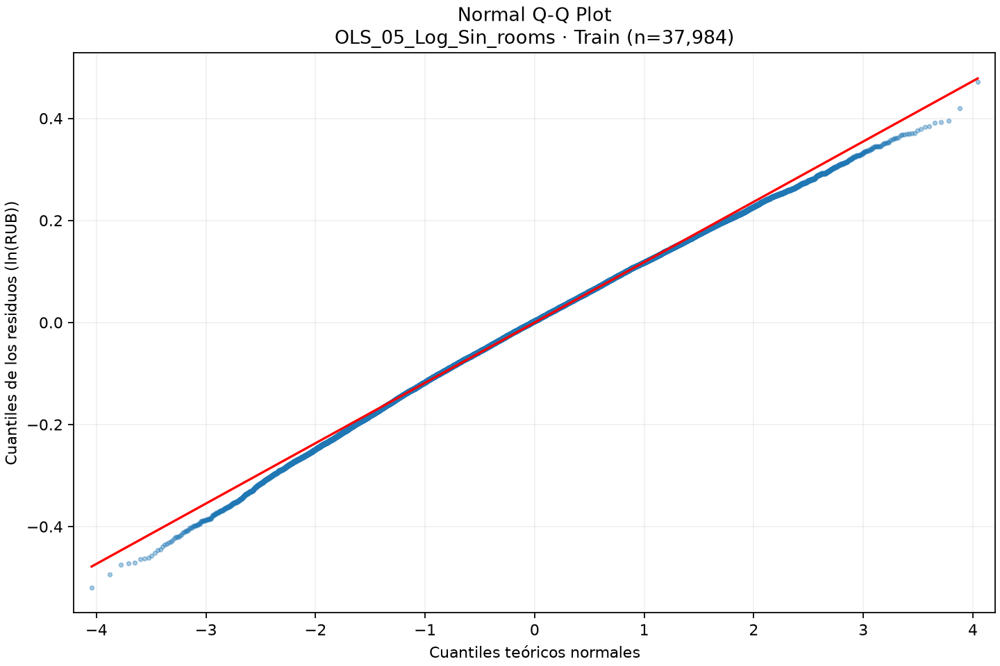

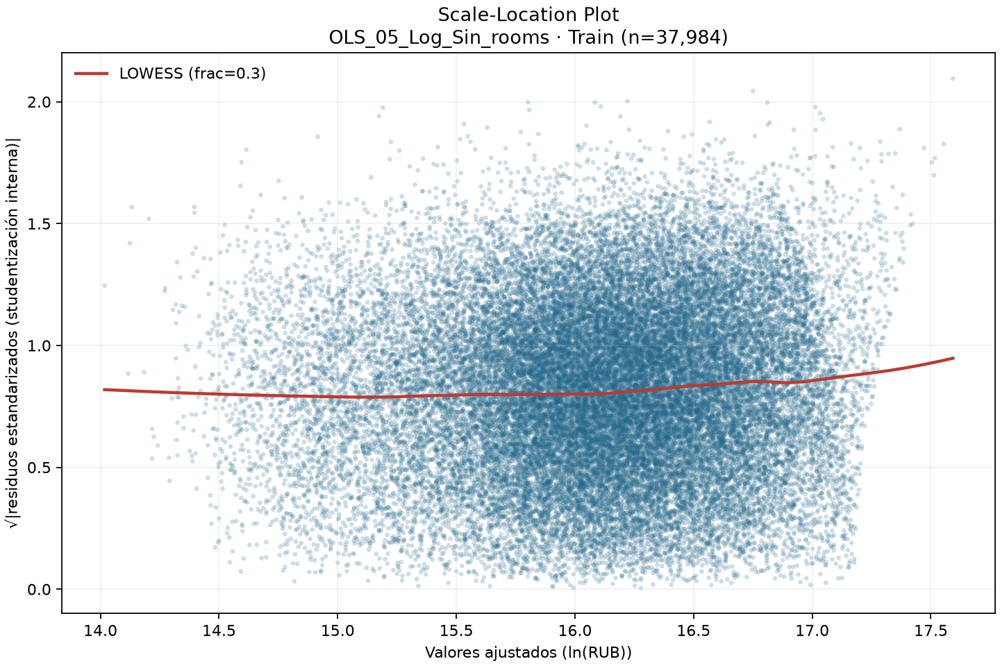

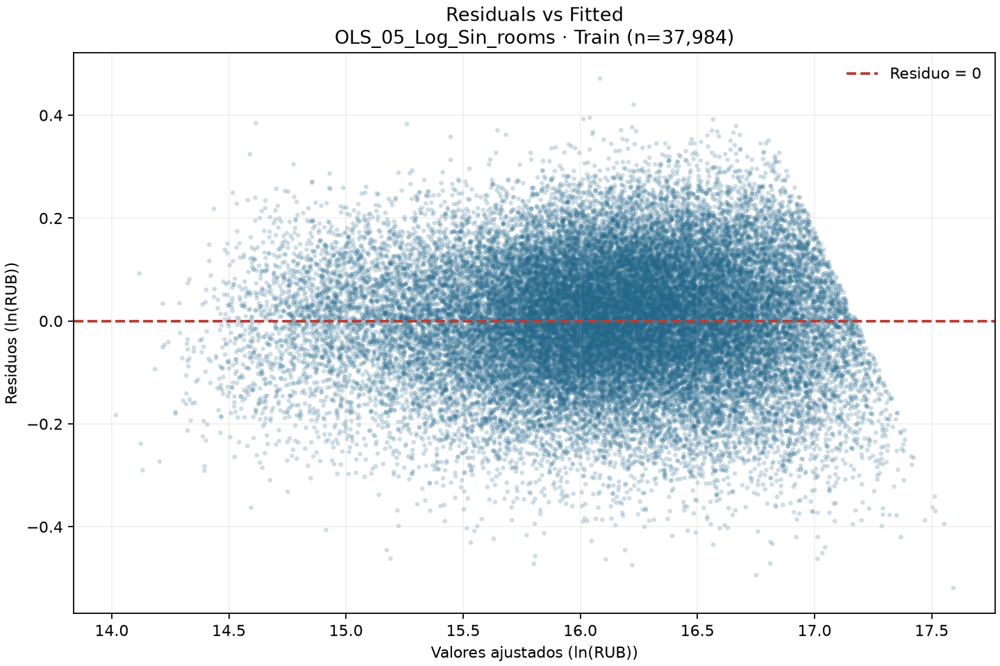

In [28]:
with sesion.paso():
    NOMBRE_05 = "OLS_05_Log_Sin_rooms"
    datos_05 = b.preparar_ablacion(cliente, base, datos_04["X"], y_ln_log, y_precio_log,
        registro_referencia=registro_04, variable="rooms", nombre_run=NOMBRE_05,
        carpeta_salida=sesion.carpeta("ols_05_log_sin_rooms"), analizar_importancia=False)
    assert datos_05["X"].shape == (37984, 174)
    assert datos_05["contexto"]["predictoras_excluidas"] == ["to_center_km", "living_area", "rooms"]
    modelo_05, diseno_05 = b.ajustar(datos_05["X"], y_ln_log)
    assert modelo_05.model.rank == 175 and int(modelo_05.nobs) == 37984
    resultado_05 = b.evaluar_ablacion(datos_05, modelo_05, diseno_05)
    assert set(resultado_05["metricas"]) == {k for k in datos_05["referencia"].data.metrics if k.startswith("train_")}
    b.pd.testing.assert_series_equal(y_precio_log, y_precio_intacto_log)
    display(Markdown(resultado_05["comparacion_md"]))
    for nombre in dr.ARCHIVOS:
        display(Image(filename=str(datos_05["salida"] / "diagnosticos_residuales" / nombre)))


In [29]:
with sesion.paso():
    registro_05 = b.registrar(cliente, datos_05["salida"], datos_05["contexto"],
        resultado_05["metricas"], nombre_run=NOMBRE_05)
    remoto_05 = cliente.get_run(registro_05["run_id"])
    ref_despues_05 = cliente.get_run(datos_05["referencia"].info.run_id)
    assert remoto_05.info.status == "FINISHED" and remoto_05.info.experiment_id == datos_05["referencia"].info.experiment_id
    assert remoto_05.data.params["excluded_predictors"] == "to_center_km,living_area,rooms"
    assert remoto_05.data.params["reference_run_id"] == datos_05["referencia"].info.run_id
    assert remoto_05.data.params["n_predictors"] == "174" and remoto_05.data.params["n_train"] == "37984"
    assert remoto_05.data.params["target_transform"] == "ln(Target)" and remoto_05.data.params["bias_correction"] == "none"
    assert all(remoto_05.data.metrics[k] == v for k,v in resultado_05["metricas"].items())
    assert ref_despues_05.info.status == datos_05["referencia"].info.status
    assert ref_despues_05.data.metrics == datos_05["referencia"].data.metrics
    assert ref_despues_05.data.params == datos_05["referencia"].data.params
    assert b.sha256(base / datos_05["contexto"]["csv"]) == datos_05["contexto"]["dataset_sha256"]
    display(Markdown(f"[{NOMBRE_05}]({registro_05['url']}) — **FINISHED**. Métricas, tabla, tres PNG y modelo verificados; referencia y Train intactos; Test no utilizado."))

    sesion.cerrar()


🏃 View run OLS_05_Log_Sin_rooms at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/f68265a7164742159c9807d91fa4f8e5
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5


[OLS_05_Log_Sin_rooms](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/f68265a7164742159c9807d91fa4f8e5) — **FINISHED**. Métricas, tabla, tres PNG y modelo verificados; referencia y Train intactos; Test no utilizado.